# AKE Lab 2 · Vom Filter zum Trägermodell — Musterlösung

**Angewandte KI & KI-Engineering · Block A – Vertiefung Deep Learning · Woche 2**
Skript: *CNNs & Computer Vision*, Abschn. 2–3, 5, 8 · Aufgabenblatt: `lab02_aufgabenblatt.pdf` (gleiche Nummern wie hier)

Musterlösung mit Ausgaben. Die Zahlen stammen aus dem Lauf, mit dem dieses Notebook erzeugt wurde (`torch.manual_seed(0)` vor jedem Modell); auf anderer Hardware weichen Laufzeiten und letzte Nachkommastellen ab, die qualitativen Aussagen nicht.


**Referenzlauf dieser Musterlösung:** Apple M4 Pro (14 Kerne), 48 GB RAM, PyTorch 2.8.0 (CPU), auf **4 Threads** begrenzt
(`OMP_NUM_THREADS=4`), keine GPU/MPS, `num_workers=0`. Reine Rechenzeit laut Zelle *Laufzeiten* am Ende:

| Teil | gemessen (4 Threads, M4 Pro) | Schätzung Referenz-Laptop (4 Kerne, Faktor ≈ 2) |
|---|---|---|
| Aufgabe 0–2 (Setup, Faltung, Bausteine) | < 1 s | ≈ 1 s |
| Aufgabe 3 (LeNet + MLP je 2 Epochen, Verschiebungstest) | 23 s | ≈ 50 s |
| Aufgabe 4 (Features 21 s, Kopf-Sweep 0,4 s, Fine-Tuning 59 s, Ablage) | 81 s | ≈ 2,7 Min. |
| Aufgabe 5 (Vorhersagen, Fehleranalyse) | 5 s | ≈ 10 s |
| **Pflichtteil gesamt** | **1,8 Min.** | **≈ 3,7 Min.** (Budget 5 Min.) |
| Optional O1–O4 (davon O3: 21 s Feature-Extraktion) | 22 s | ≈ 45 s |

Der Faktor 2 für einen typischen 4-Kern-Laptop ist geschätzt, nicht gemessen (ein M4-Pro-Leistungskern ist etwa doppelt so schnell).


**Rechenbudget (Referenz 4 Kerne / 8 GB, keine GPU):** reine Rechenzeit ≈ 5 Min. – Aufgabe 3 ≈ 1 Min., Feature-Extraktion in 4.2 ≈ 1 Min.,
Fine-Tuning in 4.4 ≈ 2–3 Min.; alles andere dauert Sekunden. Der Abschnitt *Optional* gehört nicht zum Budget.
Die Zelle **Laufzeiten** am Ende zeigt Ihre eigene Rechenzeit je Aufgabe.

**Fallback:** Jedes Experiment schreibt ein JSON-Log nach `results/` (Seed, Konfiguration, Kurven, Laufzeit). Dauert ein Lauf zu lange
oder bricht er ab, laden Sie das passende Referenzlog mit `lade_referenz("a3_lenet")` aus `results_referenz/`, bearbeiten die
Interpretation trotzdem und kennzeichnen das im Notebook.

**Arbeitsarten** (wie im Aufgabenblatt): `CODE` wenige Zeilen ergänzen · `AUSFÜHREN` vorgegebene Zelle ausführen ·
`PAPIER` erst von Hand rechnen · `DENKEN` Leitfrage beantworten (Stichpunkte genügen)

**So arbeiten Sie**
- Zellen der Reihe nach mit *Shift + Enter* ausführen. Nach einem Kernel-Neustart alles von oben erneut ausführen.
- Zu ergänzen ist nur, was mit `# TODO x.y` markiert ist: Die Zeile `raise NotImplementedError("TODO x.y")` durch Ihren Code ersetzen.
  Jede TODO-Lücke braucht 1–8 Zeilen; der Tipp im Kommentar darüber nennt die passenden Funktionen.
- Direkt nach jeder TODO-Zelle folgt eine **Prüfzelle**: ✅ heißt richtig, ❌ nennt einen Hinweis. Erst weiter, wenn alles ✅ ist.
- Fehlermeldungen von **unten** lesen: Die letzte Zeile nennt den Fehler, darüber steht die betroffene Codezeile.

## Aufgabe 0 · Setup

`AUSFÜHREN` · Die Setup-Zelle importiert alle Bibliotheken, sucht das Kursrepository (erster Elternordner mit `pyproject.toml`) und
prüft die Daten: MNIST, Imagenette5 (2 500 Trainings-/500 Validierungsbilder, 5 Klassen) und die ResNet-18-Gewichte.
Sie legt `results/` und `cache/` (hier in `lab02/`) sowie `models/` (auf Repository-Ebene, dort lesen die späteren Labs) an.
Es wird nichts heruntergeladen: Fehlt eine Datei, bricht die Zelle mit einer Meldung ab. Dann im Repository `git pull` ausführen.
**Erwartung:** alle Prüfungen ✅.

In [1]:
# --- Bibliotheken -------------------------------------------------------------------------------------
import os, sys, time, json, math, copy, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F          # F: Funktionen ohne Parameter (conv2d, max_pool2d, ...)
from torchvision import datasets, transforms
from torchvision.models import resnet18
from torch.utils.data import DataLoader, TensorDataset, random_split
import matplotlib.pyplot as plt
import yaml

torch.manual_seed(0); np.random.seed(0)
# Das ganze Lab ist fuer die CPU ausgelegt (Referenz: 4 Kerne, keine GPU). run_epoch/fit aus Lab 1 arbeiten auf der CPU.
DEVICE = torch.device("cpu")

# --- Pruefhelfer: gibt ✅ oder ❌ mit Hinweis aus, statt mit einem nackten assert abzubrechen ---------------
CHECKS = {}
def check(name, ok, hint=""):
    """ok: Wahrheitswert oder Funktion ohne Argumente (Fehler darin -> ❌ mit Fehlermeldung)."""
    try:
        ok = bool(ok() if callable(ok) else ok)
        msg = hint
    except NotImplementedError as e:
        ok, msg = False, f"{e} ist noch offen"
    except Exception as e:
        ok, msg = False, f"{type(e).__name__}: {e}" + (f" | {hint}" if hint else "")
    CHECKS[name] = ok
    print(f"✅ {name}" if ok else f"❌ {name} – Hinweis: {msg}")

# --- Laufzeitmessung: reine Rechenzeit aller Zellen, je Aufgabe aufsummiert (Tabelle am Ende des Notebooks) ---
RUNTIME, _teil = {}, {"name": "Aufgabe 0", "t0": None}
def abschnitt(name):
    """Ab jetzt zaehlt die Rechenzeit fuer `name`."""
    _teil["name"] = name
def _ake_pre(*args):
    _teil["t0"] = time.perf_counter()
def _ake_post(*args):
    if _teil["t0"] is not None:
        RUNTIME[_teil["name"]] = RUNTIME.get(_teil["name"], 0.0) + time.perf_counter() - _teil["t0"]
try:
    _ip = get_ipython()
    for ev, fn in (("pre_run_cell", _ake_pre), ("post_run_cell", _ake_post)):
        for old in [f for f in _ip.events.callbacks[ev] if getattr(f, "__name__", "") == fn.__name__]:
            _ip.events.unregister(ev, old)                  # bei erneutem Ausfuehren nicht doppelt zaehlen
        _ip.events.register(ev, fn)
except NameError:
    pass                                                    # ausserhalb von Jupyter: keine Messung

# --- Pfade: REPO_ROOT = erster Elternordner mit pyproject.toml ----------------------------------------------
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Kein Kursrepository gefunden (kein Ordner mit pyproject.toml oberhalb von "
                            f"{Path.cwd()}). Bitte Jupyter im Ordner des Repositorys starten und lab02/ oeffnen.")
DATA    = REPO_ROOT / "data"                     # MNIST/, imagenette5/, models/ (ResNet-18-Gewichte)
MODELS  = REPO_ROOT / "models"                   # Traegermodell: spaetere Labs lesen hier
RESULTS = Path("results")                        # JSON-Logs je Experiment (relativ zu lab02/)
CACHE   = Path("cache")                          # gecachte Features (Aufgabe 4.2)
IMG     = DATA / "imagenette5"
WEIGHTS = DATA / "models" / "resnet18-f37072fd.pth"

sys.path.insert(0, str(REPO_ROOT))
from src.traeger import (Imagenette5, make_transform, build_model, set_trainable, train_mode, load_traeger,
                         IMAGENET_MEAN, IMAGENET_STD, SIZE)

print(f"torch {torch.__version__} | Geraet: {DEVICE} | Threads: {torch.get_num_threads()} | CPU-Kerne: {os.cpu_count()}")
print(f"REPO_ROOT: {REPO_ROOT}\n")

# --- Pruefungen -------------------------------------------------------------------------------------------
check("MNIST in data/MNIST/raw", all((DATA / "MNIST" / "raw" / f).exists() for f in
                 ["train-images-idx3-ubyte", "train-labels-idx1-ubyte", "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]),
      "Ordner data/MNIST/raw fehlt oder ist unvollstaendig -> git pull")
def _liste(split):
    f = IMG / f"{split}.txt"
    return f.read_text().strip().splitlines() if f.exists() else []
n_tr, n_va = len(_liste("train")), len(_liste("val"))
n_cls = len(json.loads((IMG / "classes.json").read_text())) if (IMG / "classes.json").exists() else 0
fehlend = [l.split("\t")[0] for l in _liste("train") + _liste("val") if not (IMG / l.split("\t")[0]).exists()]
check(f"Imagenette5: {n_tr} Train / {n_va} Val / {n_cls} Klassen, alle Bilddateien vorhanden",
      (n_tr, n_va, n_cls) == (2500, 500, 5) and not fehlend,
      f"erwartet 2500/500/5; {len(fehlend)} Bilddateien fehlen -> data/imagenette5 aus dem Repository neu holen")
check("ResNet-18-Gewichte in data/models", WEIGHTS.exists(), f"{WEIGHTS} fehlt -> git pull")
if WEIGHTS.exists():
    WEIGHTS_SHA = hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()[:12]
    check(f"Gewichte unveraendert (sha256[:12] = {WEIGHTS_SHA})", WEIGHTS_SHA == "f37072fd47e8",
          "Datei beschaedigt; erwartet f37072fd47e8 (torchvision IMAGENET1K_V1)")
for d in (RESULTS, CACHE, MODELS):
    d.mkdir(exist_ok=True)
check("Ordner results/, cache/, models/ angelegt", all(d.is_dir() for d in (RESULTS, CACHE, MODELS)))
if not all(CHECKS.values()):
    raise FileNotFoundError("Daten unvollstaendig (siehe ❌ oben). Im Repository 'git pull' ausfuehren und "
                            "die Setup-Zelle erneut starten.")

torch 2.8.0 | Geraet: cpu | Threads: 10 | CPU-Kerne: 14
REPO_ROOT: /Users/stefan/Documents/02_PHWT/DS-Vorlesung/03_Git_Studierende

✅ MNIST in data/MNIST/raw
✅ Imagenette5: 2500 Train / 500 Val / 5 Klassen, alle Bilddateien vorhanden
✅ ResNet-18-Gewichte in data/models
✅ Gewichte unveraendert (sha256[:12] = f37072fd47e8)
✅ Ordner results/, cache/, models/ angelegt


MNIST: Train 54000 | Val 6000 | Test 10000
Imagenette5-Klassen (feste Reihenfolge): ['Kettensaege', 'Kirche', 'Kassettenrecorder', 'Golfball', 'Fallschirm']


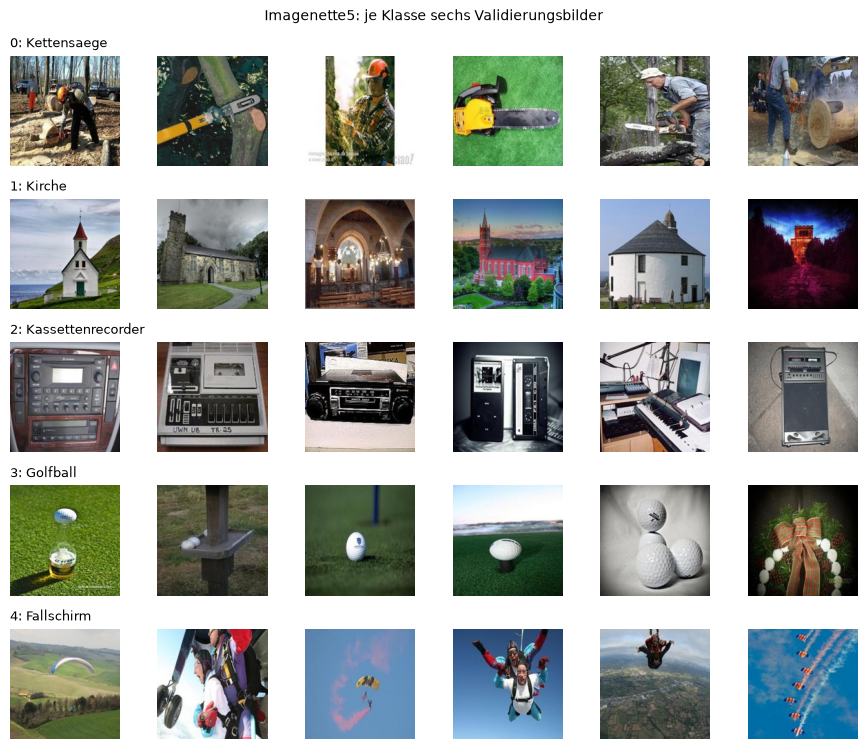

In [2]:
# --- MNIST: Splits und Normalisierung exakt wie in Lab 1 (54 000 / 6 000 / 10 000) ---------------------
tf = transforms.Compose([transforms.ToTensor(),
                         transforms.Normalize((0.1307,), (0.3081,))])   # Mittelwert/Std von MNIST
full = datasets.MNIST(DATA, train=True,  download=False, transform=tf)
test = datasets.MNIST(DATA, train=False, download=False, transform=tf)
train, val = random_split(full, [54_000, 6_000], generator=torch.Generator().manual_seed(0))

def make_loaders(train_ds=train, batch_size=64):
    """Train-Loader wird gemischt, Val/Test nicht. Val/Test sind immer die vollen Splits."""
    return {"train": DataLoader(train_ds, batch_size=batch_size, shuffle=True),
            "val":   DataLoader(val,      batch_size=256),
            "test":  DataLoader(test,     batch_size=256)}

dl = make_loaders()
print(f"MNIST: Train {len(train)} | Val {len(val)} | Test {len(test)}")

# --- Imagenette5: Klassenreihenfolge NUR aus classes.json, Splits NUR aus train.txt / val.txt ---------------
raw_val = Imagenette5(IMG, "val")                # ohne Transform -> PIL-Bilder zum Anzeigen
CLASSES = raw_val.classes                         # aus classes.json, nie aus os.listdir
print("Imagenette5-Klassen (feste Reihenfolge):", CLASSES)

fig, ax = plt.subplots(5, 6, figsize=(9, 7.6))
for c in range(5):
    idx = [i for i, (_, y) in enumerate(raw_val.items) if y == c][:6]
    for j, i in enumerate(idx):
        ax[c, j].imshow(raw_val[i][0]); ax[c, j].axis("off")
    ax[c, 0].set_title(f"{c}: {CLASSES[c]}", fontsize=9, loc="left")
fig.suptitle("Imagenette5: je Klasse sechs Validierungsbilder", fontsize=10)
plt.tight_layout(); plt.show()

### Werkzeuge aus Lab 1 (unverändert) und neue Helfer

`MLP`, `run_epoch`, `fit` und `plot_history` sind **unverändert** aus Lab 1 übernommen. Die Schleife kennt keine Architektur,
nur `model(x)`, und funktioniert deshalb für LeNet genauso wie für das MLP. Neu sind `save_log` (JSON-Log mit Seed, Konfiguration,
Kurven, Laufzeit) und `lade_referenz` (Fallback).

In [3]:
class MLP(nn.Module):
    """MLP 784 -> hidden[0] -> ... -> n_classes. Ausgabe sind Logits (Softmax steckt im Loss).
    act: Aktivierungsklasse (nn.ReLU, nn.Sigmoid, ...); dropout: p nach jeder Aktivierung."""
    def __init__(self, d_in=784, hidden=(128, 128), n_classes=10, act=nn.ReLU, dropout=0.0, init="default"):
        super().__init__()
        layers, d = [nn.Flatten()], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), act()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, n_classes))                 # Logits, kein Softmax!
        self.net = nn.Sequential(*layers)
        self.reset_parameters(init)

    def reset_parameters(self, init):
        """init: "default" (PyTorch: kaiming_uniform mit a=sqrt(5), d.h. Var = 1/(3 n_in)),
        "glorot" (Var = 2/(n_in+n_out), Gl. 24) oder "he" (Var = 2/n_in, Gl. 25). Biases = 0."""
        if init == "default":
            return
        for m in self.net:
            if isinstance(m, nn.Linear):
                {"glorot": nn.init.xavier_normal_,
                 "he": lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")}[init](m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)

lossf = nn.CrossEntropyLoss()   # erwartet Logits, kein Softmax davor!

def run_epoch(model, loader, opt=None):
    """Eine Epoche. opt=None => reine Evaluation (kein Gradient, eval()-Modus)."""
    train_mode = opt is not None
    model.train(train_mode)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            logits = model(x)
            loss = lossf(logits, y)
            if train_mode:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y)
            correct  += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, correct / n

def fit(model, opt, loaders, epochs, name=None, patience=None, verbose=True):
    """Trainiert `epochs` Epochen, loggt Train-/Val-Verlust und -Genauigkeit.
    patience=k: Early Stopping — Abbruch nach k Epochen ohne Verbesserung des Val-Verlusts,
    beste Parameter werden wiederhergestellt. Rueckgabe: history-Dict (auch als JSON in results/)."""
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_loss, best_state, bad = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = run_epoch(model, loaders["train"], opt)
        va = run_epoch(model, loaders["val"])
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], (*tr, *va)):
            hist[k].append(v)
        hist["epoch_time"].append(time.time() - t0)
        if verbose:
            print(f"  Epoche {ep:3d}: train loss {tr[0]:.4f} acc {tr[1]:.2%} | "
                  f"val loss {va[0]:.4f} acc {va[1]:.2%} | {hist['epoch_time'][-1]:.1f}s")
        if not math.isfinite(va[0]):
            print("  -> Verlust nicht endlich, Abbruch."); break
        if va[0] < best_loss:
            best_loss, bad = va[0], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience is not None and bad >= patience:
                print(f"  -> Early Stopping nach Epoche {ep} (bestes Val-Loss {best_loss:.4f} "
                      f"in Epoche {ep - bad}).")
                break
    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)          # Parameterstand am Val-Minimum behalten
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    if name:
        (RESULTS / f"{name}.json").write_text(json.dumps(hist, indent=1))
    return hist

def plot_history(hists, title="", metric="loss", ax=None, logy=False):
    """hists: {label: history}. Zeichnet Train (durchgezogen) und Val (gestrichelt)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.6))
    for i, (label, h) in enumerate(hists.items()):
        c = f"C{i}"
        ax.plot(range(1, len(h[f"train_{metric}"]) + 1), h[f"train_{metric}"], c, label=f"{label} (train)")
        ax.plot(range(1, len(h[f"val_{metric}"]) + 1),   h[f"val_{metric}"],   c + "--", label=f"{label} (val)")
    ax.set_xlabel("Epoche"); ax.set_ylabel(metric); ax.set_title(title); ax.grid(alpha=.3)
    if logy: ax.set_yscale("log")
    ax.legend(fontsize=7)
    return ax

# ---------------------------------------------------------------- neu in diesem Lab
def save_log(name, hist=None, **extra):
    """JSON-Log in results/: Seed, Konfiguration, Kurven, Laufzeit (Debug-Protokoll: jeden Lauf loggen)."""
    log = {"seed": 0, "torch": torch.__version__, "threads": torch.get_num_threads(), **(hist or {}), **extra}
    (RESULTS / f"{name}.json").write_text(json.dumps(log, indent=1, ensure_ascii=False, default=float))
    return log

def lade_referenz(name):
    """Fallback: mitgeliefertes Referenzlog aus results_referenz/<name>.json als Dict."""
    return json.loads((Path("results_referenz") / f"{name}.json").read_text())

## Aufgabe 1 · Die Faltung von Hand

`CODE` 1.1–1.3 · `AUSFÜHREN` 1.4 · `DENKEN` Interpretation · Skript Def. 2.1, Abb. 2, Bsp. 2.2, Satz 2.3 · ≈ 15 Min.

**Intuition.** Ein Filter ist eine Schablone, die über das Bild geschoben wird. An jeder Position legt man sie auf den
gleich großen Bildausschnitt, multipliziert Feld für Feld und addiert. Die Antwort ist groß, wo der Ausschnitt der Schablone
ähnelt, also leuchtet die Feature Map dort auf, wo das Muster im Bild vorkommt. Formal (Gl. 1):

$$C(j,k)=\sum_{l=0}^{M-1}\sum_{m=0}^{M-1} I(j+l,\,k+m)\,K(l,m).$$

Mit Padding $P$ und Stride $S$ ist die Ausgabe $\left\lfloor\frac{J+2P-M}{S}\right\rfloor+1$ Pixel breit (Gl. 2).

In [4]:
abschnitt("Aufgabe 1")
# Testfall aus Skript Abb. 2: 4x4-Bild, 2x2-Kernel, ohne Padding, Stride 1
I_fig = np.array([[ 2,  5, -3,  0],
                  [ 0,  6,  0, -4],
                  [-1, -3,  0,  2],
                  [ 5,  0,  0,  3]], dtype=float)
K_fig = np.array([[-2, 0],
                  [ 4, 6]], dtype=float)
C_fig = np.array([[ 32,  14, -18],
                  [-22, -24,  12],
                  [ 22,   6,  18]], dtype=float)            # Erwartung laut Abb. 2
print("C(0,0) = 2*(-2) + 5*0 + 0*4 + 6*6 =", 2*(-2) + 5*0 + 0*4 + 6*6)

C(0,0) = 2*(-2) + 5*0 + 0*4 + 6*6 = 32


### 1.1 `conv2d_np(I, K)` als Doppelschleife

`CODE` · Ohne Padding, Stride 1. Die Ausgabe hat $(J-M+1)\times(K-M+1)$ Einträge; jeder ist ein Skalarprodukt aus Ausschnitt und Kernel.

In [5]:
def conv2d_np(I: np.ndarray, K: np.ndarray) -> np.ndarray:
    """Faltung (Kreuzkorrelation) nach Gl. (1): ein Kanal, kein Padding, Stride 1.
    I: Bild (J x Kb), K: Kernel (M x M). Rueckgabe: Feature Map ((J-M+1) x (Kb-M+1))."""
    J, Kb = I.shape
    M = K.shape[0]
    C = np.zeros((J - M + 1, Kb - M + 1))
    # TODO 1.1: Doppelschleife ueber alle Positionen (j, k) von C. Je Position: Ausschnitt I[j:j+M, k:k+M],
    #           elementweise mal K, dann .sum() -> in C[j, k] schreiben.
    for j in range(C.shape[0]):
        for k in range(C.shape[1]):
            C[j, k] = (I[j:j + M, k:k + M] * K).sum()
    return C

In [6]:
# Pruefzelle 1.1
check("1.1 Abb. 2: conv2d_np(I, K) ergibt C", lambda: np.allclose(conv2d_np(I_fig, K_fig), C_fig),
      "Form 3x3? Ausschnitt I[j:j+M, k:k+M] (nicht j+M-1) und Summe ueber das Produkt")
check("1.1 Ausgabeform 26x26 fuer 28x28-Bild und 3x3-Kernel", lambda: conv2d_np(np.ones((28, 28)), np.ones((3, 3))).shape == (26, 26))

✅ 1.1 Abb. 2: conv2d_np(I, K) ergibt C
✅ 1.1 Ausgabeform 26x26 fuer 28x28-Bild und 3x3-Kernel


### 1.2 Padding, Stride und Ausgabegröße

`CODE` · `out_size(J, M, P, S)` setzt Gl. (2) um. `conv2d_np` bekommt die Parameter `P` und `S`: erst das Bild mit `np.pad` um
$P$ Nullen pro Rand auffüllen, dann den Kernel in Sprüngen von $S$ Pixeln schieben. Die neue Definition ersetzt die aus 1.1;
mit `P=0, S=1` muss sie dasselbe liefern.

In [7]:
def out_size(J: int, M: int, P: int = 0, S: int = 1) -> int:
    """Ausgabegroesse einer Faltung nach Gl. (2): floor((J + 2P - M) / S) + 1."""
    # TODO 1.2a: Gl. (2) in einer Zeile; // ist die ganzzahlige Division (floor)
    return (J + 2 * P - M) // S + 1

def conv2d_np(I: np.ndarray, K: np.ndarray, P: int = 0, S: int = 1) -> np.ndarray:
    """Faltung nach Gl. (1) mit Padding P (Nullen) und Stride S, ein Kanal."""
    M = K.shape[0]
    C = np.zeros((out_size(I.shape[0], M, P, S), out_size(I.shape[1], M, P, S)))
    # TODO 1.2b: Ip = np.pad(I, P) fuellt alle Raender mit P Nullen auf. Dann wie in 1.1, aber der Ausschnitt
    #            beginnt bei (j*S, k*S): Ip[j*S : j*S+M, k*S : k*S+M]
    Ip = np.pad(I, P)
    for j in range(C.shape[0]):
        for k in range(C.shape[1]):
            C[j, k] = (Ip[j * S:j * S + M, k * S:k * S + M] * K).sum()
    return C

In [8]:
# Pruefzelle 1.2
check("1.2 out_size(28, 5, 2, 1) == 28  (same, LeNet C1)", lambda: out_size(28, 5, 2, 1) == 28)
check("1.2 out_size(224, 7, 3, 2) == 112  (erste Schicht von ResNet)", lambda: out_size(224, 7, 3, 2) == 112)
check("1.2 out_size(4, 2, 1, 2) == 3", lambda: out_size(4, 2, 1, 2) == 3, "Klammern: (J + 2P - M) // S + 1")
check("1.2 P=0, S=1 liefert weiterhin Abb. 2", lambda: np.allclose(conv2d_np(I_fig, K_fig), C_fig))
C_ps = np.array([[12, 2, 0], [-6, -24, 16], [0, 0, -6]], dtype=float)
check("1.2 Abb. 2 mit P=1, S=2 ergibt [[12,2,0],[-6,-24,16],[0,0,-6]]",
      lambda: np.allclose(conv2d_np(I_fig, K_fig, P=1, S=2), C_ps),
      "zuerst np.pad(I, P), dann Ausschnitt ab (j*S, k*S)")

✅ 1.2 out_size(28, 5, 2, 1) == 28  (same, LeNet C1)
✅ 1.2 out_size(224, 7, 3, 2) == 112  (erste Schicht von ResNet)
✅ 1.2 out_size(4, 2, 1, 2) == 3
✅ 1.2 P=0, S=1 liefert weiterhin Abb. 2
✅ 1.2 Abb. 2 mit P=1, S=2 ergibt [[12,2,0],[-6,-24,16],[0,0,-6]]


### 1.3 Gegenprobe mit `F.conv2d`

`CODE` · PyTorch rechnet dieselbe Kreuzkorrelation (Def. 2.1). **Häufigste Fehlerquelle laut Skript (Abschn. 3.3, Praxis-Box):**
`F.conv2d` erwartet 4D-Tensoren im Format $(N, C, H, W)$ – Batch, Kanäle, Höhe, Breite – und den Kernel als
$(C_\text{out}, C_\text{in}, M, M)$. Das $4\times4$-Bild wird also zu $(1,1,4,4)$, der Kernel zu $(1,1,2,2)$.

In [9]:
def conv2d_torch(I: np.ndarray, K: np.ndarray, P: int = 0, S: int = 1) -> np.ndarray:
    """Dieselbe Faltung mit F.conv2d. Rueckgabe wieder als 2D-NumPy-Array."""
    # TODO 1.3: Bild und Kernel in float32-Tensoren im NCHW-Format umformen:
    #           x = torch.tensor(I, dtype=torch.float32).reshape(1, 1, *I.shape), Kernel analog -> (1, 1, M, M).
    #           Dann F.conv2d(x, w, padding=P, stride=S) und mit [0, 0] Batch- und Kanalachse wieder entfernen, .numpy()
    x = torch.tensor(I, dtype=torch.float32).reshape(1, 1, *I.shape)
    w = torch.tensor(K, dtype=torch.float32).reshape(1, 1, *K.shape)
    return F.conv2d(x, w, padding=P, stride=S)[0, 0].numpy()

In [10]:
# Pruefzelle 1.3: torch.allclose vergleicht elementweise mit Toleranz
def _vergleich(I, K, P, S):
    return torch.allclose(torch.tensor(conv2d_torch(I, K, P, S)), torch.tensor(conv2d_np(I, K, P, S), dtype=torch.float32), atol=1e-4)
check("1.3 F.conv2d == conv2d_np auf Abb. 2 (P=0, S=1)", lambda: _vergleich(I_fig, K_fig, 0, 1),
      "Form (1, 1, 4, 4) bzw. (1, 1, 2, 2)? Ergebnis mit [0, 0] auf 2D zurueckgeformt?")
check("1.3 F.conv2d == conv2d_np auf Abb. 2 (P=1, S=2)", lambda: _vergleich(I_fig, K_fig, 1, 2), "padding=P, stride=S uebergeben")
rng = np.random.default_rng(0)
check("1.3 zufaelliges 28x28-Bild, 5x5-Kernel, P=2", lambda: _vergleich(rng.normal(size=(28, 28)), rng.normal(size=(5, 5)), 2, 1))

✅ 1.3 F.conv2d == conv2d_np auf Abb. 2 (P=0, S=1)
✅ 1.3 F.conv2d == conv2d_np auf Abb. 2 (P=1, S=2)
✅ 1.3 zufaelliges 28x28-Bild, 5x5-Kernel, P=2


### 1.4 Kantendetektoren auf echten Bildern

`AUSFÜHREN` · $K_\text{vert}$ aus Bsp. 2.2 misst die Helligkeitsänderung von links nach rechts, $K_\text{hor}=K_\text{vert}^\top$
die von oben nach unten. Beide werden mit Ihrer Funktion (`P=1`, Ausgabe so groß wie das Bild) auf ein synthetisches Bild
(Quadrat, Kreis, Balken wie in Abb. 3) und auf eine MNIST-Ziffer angewendet. Farbskala: blau negativ, weiß null, rot positiv.

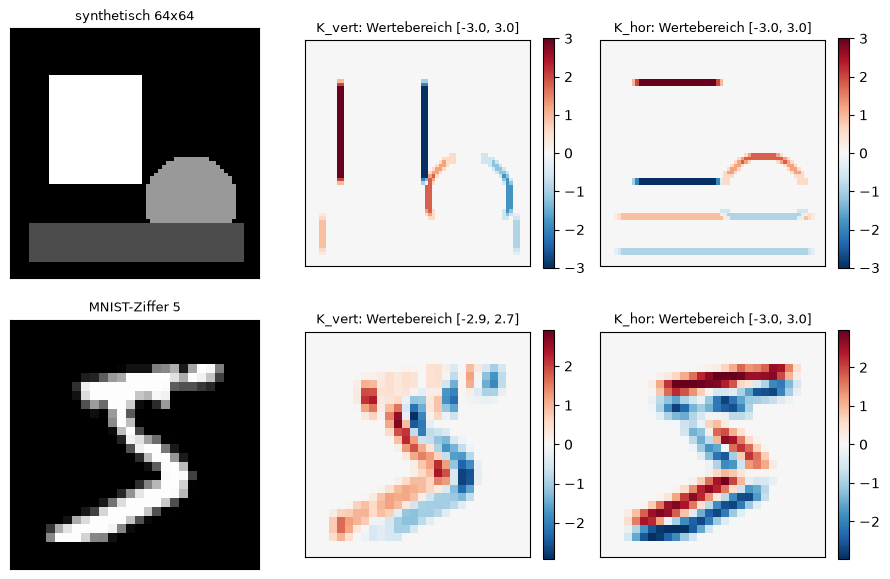

Antwort im Inneren des Rechtecks (homogen): 0.0


In [11]:
K_vert = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]], dtype=float)         # Bsp. 2.2
K_hor = K_vert.T

# Synthetisches 64x64-Bild wie Skript Abb. 3 (ohne Rauschen, damit homogene Flaechen exakt 0 ergeben)
synth = np.zeros((64, 64))
synth[12:40, 10:34] = 1.0                                       # helles Rechteck
yy, xx = np.mgrid[0:64, 0:64]
synth[(yy - 44) ** 2 + (xx - 46) ** 2 < 12 ** 2] = 0.6           # Kreis
synth[50:60, 5:60] = 0.3                                        # Balken
ziffer = full.data[0].numpy() / 255.0                           # eine Trainingsziffer (0..1), keine Testdaten

fig, ax = plt.subplots(2, 3, figsize=(9, 6))
for r, (bild, name) in enumerate([(synth, "synthetisch 64x64"), (ziffer, f"MNIST-Ziffer {full.targets[0].item()}")]):
    ax[r, 0].imshow(bild, cmap="gray"); ax[r, 0].set_title(name, fontsize=9)
    for c, (K, kname) in enumerate([(K_vert, "K_vert"), (K_hor, "K_hor")], start=1):
        antwort = conv2d_np(bild, K, P=1)                         # Ihre Funktion aus 1.2
        v = np.abs(antwort).max()                                 # symmetrische Grenzen: 0 = weiss
        im = ax[r, c].imshow(antwort, cmap="RdBu_r", vmin=-v, vmax=v)
        ax[r, c].set_title(f"{kname}: Wertebereich [{antwort.min():.1f}, {antwort.max():.1f}]", fontsize=9)
        plt.colorbar(im, ax=ax[r, c], fraction=0.046)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print("Antwort im Inneren des Rechtecks (homogen):", conv2d_np(synth, K_vert, P=1)[25, 20])

### Interpretation Aufgabe 1

`DENKEN` · Leitfragen aus dem Aufgabenblatt:
- Warum ist die Filterantwort auf homogenen Flächen null, und was codiert ihr Vorzeichen?
- $K_\text{vert}$ hat 9 Gewichte. Eine vollverbundene Schicht, die aus einem $28\times28$-Bild eine gleich große Ausgabe berechnet,
  hätte $784\cdot784=614\,656$. Welche zwei Ideen aus Abschn. 2.2 erklären diesen Unterschied?

**Antwort (Musterlösung):**


- **Null auf homogenen Flächen:** Die Gewichte von $K_\text{vert}$ summieren sich zu 0 (Spalten −3, 0, +3). Auf einer Fläche mit
  konstantem Wert $c$ liefert Gl. (1) deshalb $c\cdot\sum_{l,m}K(l,m)=0$. Gemessen: im Inneren des Rechtecks exakt 0,0 (weiß im Plot).
  Der Filter reagiert nur auf *Änderungen*, nicht auf die Helligkeit selbst.
- **Vorzeichen = Richtung des Übergangs:** Rot (positiv), wo es von links nach rechts heller wird (linke Rechteckkante 0 → 1: +3),
  blau (negativ), wo es dunkler wird (rechte Kante: −3). Der Betrag ist Kontrast × 3 (Rechteck ±3, Balken ±0,9). $K_\text{hor}$
  zeigt dasselbe für oben/unten. Bei der MNIST-Ziffer erscheint jeder Strich als rot-blaues Paar (Strichanfang und -ende) – genau
  das Bild aus Bsp. 2.2 und Abb. 3.
- **9 statt 614 656 Gewichte:** Abschn. 2.2 nennt *spärliche Interaktionen* (jede Ausgabe hängt nur von $M^2=9$ statt von allen
  784 Pixeln ab: 784 · 9 = 7 056 statt 614 656 Verbindungen) und *Parameterteilung* (dieselben 9 Gewichte an allen 784 Positionen:
  aus 7 056 Verbindungen werden 9 Parameter). Zusammen ist das der „unendlich starke Prior“ der Merke-Box: eine vollverbundene
  Schicht, deren Gewichte fast alle null und die übrigen gleich sind. Die dritte Idee, Äquivarianz, wird in Aufgabe 3 sichtbar.

## Aufgabe 2 · Bausteine zählen – Parameter, Pooling, Formen

`CODE` 2.1, 2.3 · `PAPIER` + `CODE` 2.2 · `DENKEN` Interpretation · Skript Satz 2.4, Listing 1, Def. 3.1, Tab. 2, Listing 2 · ≈ 10 Min.

**Intuition.** Eine Faltungsschicht ist eine Werkzeugkiste aus $C_\text{out}$ Schablonen, jede so tief wie die Eingabe Kanäle hat.
Wie groß das Bild ist, spielt für die Zahl der Gewichte keine Rolle – dieselbe Schablone wird überall wiederverwendet (Gl. 3):

$$\#\text{Parameter}=(M^2\,C_\text{in}+1)\,C_\text{out}.$$

Pooling ist dagegen eine feste Lupe ohne Gewichte: Es fasst jedes $2\times2$-Fenster zu einer Zahl zusammen (Maximum oder Mittelwert)
und halbiert so Höhe und Breite.

In [12]:
abschnitt("Aufgabe 2")
def n_params_conv(M: int, C_in: int, C_out: int) -> int:
    """Parameterzahl einer Faltungsschicht mit Bias nach Gl. (3)."""
    # TODO 2.1: Gl. (3) in einer Zeile -- je Filter M*M*C_in Gewichte plus ein Bias
    return (M * M * C_in + 1) * C_out

In [13]:
# Pruefzelle 2.1: Vergleich mit PyTorch
n_conv = sum(p.numel() for p in nn.Conv2d(3, 64, 3).parameters())
check(f"2.1 n_params_conv(3, 3, 64) == 1 792 == nn.Conv2d(3, 64, 3) ({n_conv})",
      lambda: n_params_conv(3, 3, 64) == 1792 == n_conv, "(M*M*C_in + 1) * C_out")
check("2.1 LeNet C1 (5x5, 1 -> 6) = 156 und C3 (5x5, 6 -> 16) = 2 416 (Tab. 2)",
      lambda: (n_params_conv(5, 1, 6), n_params_conv(5, 6, 16)) == (156, 2416))

# Block aus Listing 1: Conv ohne Bias + BatchNorm. bias=False spart 64 Parameter (BN lernt einen eigenen Offset beta),
# BatchNorm2d(64) bringt 2*64 lernbare Parameter (gamma, beta) mit. Laufende Mittelwerte sind Buffers, keine Parameter.
block = nn.Sequential(nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU())
n_block = sum(p.numel() for p in block.parameters())
check(f"2.1 Listing-1-Block: {n_block} == 1 792 - 64 + 2*64 == 1 856", lambda: n_block == n_params_conv(3, 3, 64) - 64 + 2 * 64 == 1856)

✅ 2.1 n_params_conv(3, 3, 64) == 1 792 == nn.Conv2d(3, 64, 3) (1792)
✅ 2.1 LeNet C1 (5x5, 1 -> 6) = 156 und C3 (5x5, 6 -> 16) = 2 416 (Tab. 2)
✅ 2.1 Listing-1-Block: 1856 == 1 792 - 64 + 2*64 == 1 856


### 2.2 Pooling – erst auf Papier

`PAPIER` · Rechnen Sie Max- und Average-Pooling ($2\times2$, Stride 2, Def. 3.1) von Hand, **bevor** Sie die Zelle darunter ausführen:

$$F=\begin{pmatrix}1&3&2&0\\4&6&1&1\\0&2&5&7\\1&1&3&2\end{pmatrix}\qquad
\text{MaxPool}(F)=\begin{pmatrix}\;?\;&\;?\;\\\;?\;&\;?\;\end{pmatrix}\qquad
\text{AvgPool}(F)=\begin{pmatrix}\;?\;&\;?\;\\\;?\;&\;?\;\end{pmatrix}$$

`CODE` · Dann mit `F.max_pool2d` und `F.avg_pool2d` prüfen. (Die Matrix heißt im Code `F_map`, weil `F` schon für `torch.nn.functional` steht.)

In [14]:
F_map = torch.tensor([[1, 3, 2, 0],
                      [4, 6, 1, 1],
                      [0, 2, 5, 7],
                      [1, 1, 3, 2]], dtype=torch.float32)

def pooling(F_map: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """(MaxPool, AvgPool) mit 2x2-Fenster und Stride 2, Rueckgabe jeweils als 2D-Tensor."""
    # TODO 2.2: F_map[None, None] hat die Form (1, 1, 4, 4) = (N, C, H, W). F.max_pool2d(x, 2) und F.avg_pool2d(x, 2)
    #           (Stride = Fenstergroesse ist Standard), danach mit [0, 0] wieder 2D.
    x = F_map[None, None]
    return F.max_pool2d(x, 2)[0, 0], F.avg_pool2d(x, 2)[0, 0]

In [15]:
# Pruefzelle 2.2 -- vergleichen Sie auch mit Ihrer Rechnung auf Papier
check("2.2 MaxPool(F) == [[6, 2], [2, 7]]", lambda: torch.equal(pooling(F_map)[0], torch.tensor([[6., 2.], [2., 7.]])),
      "Fenster 2x2, Stride 2 -> Ergebnis 2x2")
check("2.2 AvgPool(F) == [[3.5, 1], [1, 4.25]]", lambda: torch.allclose(pooling(F_map)[1], torch.tensor([[3.5, 1.], [1., 4.25]])))
check("2.2 Pooling hat keine Parameter", sum(p.numel() for p in nn.MaxPool2d(2).parameters()) == 0)

✅ 2.2 MaxPool(F) == [[6, 2], [2, 7]]
✅ 2.2 AvgPool(F) == [[3.5, 1], [1, 4.25]]
✅ 2.2 Pooling hat keine Parameter


### 2.3 LeNet-5: die Formkette

`CODE` · Die Klasse `LeNet` ist Listing 2. Offen ist nur die Eingangsgröße `N_FLAT` der ersten linearen Schicht (F5) – laut
Praxis-Box in Abschn. 3.3 der häufigste Fehler beim Bau eines CNN. Danach schickt die Prüfzelle `torch.zeros(1, 1, 28, 28)`
Schicht für Schicht durch `model.features` und vergleicht mit Tab. 2.

In [16]:
class LeNet(nn.Module):
    """LeNet-5, heutige Variante (ReLU, Max-Pooling), Skript Listing 2 / Tab. 2. Ausgabe: Logits."""
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.ReLU(),   # C1
            nn.MaxPool2d(2),                                        # S2
            nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),             # C3
            nn.MaxPool2d(2),                                        # S4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(N_FLAT, 120), nn.ReLU(),                      # F5: N_FLAT aus TODO 2.3
            nn.Linear(120, 84), nn.ReLU(),                          # F6
            nn.Linear(84, n_classes),                               # Logits -> CrossEntropyLoss
        )
    def forward(self, x):                                           # x: (N, 1, 28, 28)
        return self.classifier(self.features(x))

In [17]:
# TODO 2.3: Eingangsgroesse von F5 = Kanaele * Hoehe * Breite der Ausgabe von S4. Kette mit Gl. (2) durchrechnen:
#           28 --C1 (M=5, P=2)--> ? --S2 (2x2)--> ? --C3 (M=5, P=0)--> ? --S4 (2x2)--> ?   (C3 hat 16 Kanaele)
N_FLAT = 16 * 5 * 5

In [18]:
# Pruefzelle 2.3: Formkette Schicht fuer Schicht (Praxis-Box Abschn. 3.3) und Vergleich mit Tab. 2
if "N_FLAT" not in globals():
    raise NotImplementedError("TODO 2.3: zuerst N_FLAT in der Zelle oben eintragen")
torch.manual_seed(0)
lenet = LeNet()
x = torch.zeros(1, 1, 28, 28)
zeilen = [("Eingabe", tuple(x.shape), 0)]
for layer in lenet.features:
    x = layer(x)
    zeilen.append((layer.__class__.__name__, tuple(x.shape), sum(p.numel() for p in layer.parameters())))
for layer in lenet.classifier:
    x = layer(x)
    zeilen.append((layer.__class__.__name__, tuple(x.shape), sum(p.numel() for p in layer.parameters())))
display(pd.DataFrame(zeilen, columns=["Schicht", "Form (N, C, H, W)", "Parameter"]))
n_lenet = sum(p.numel() for p in lenet.parameters())
check("2.3 Form vor dem Flatten (1, 16, 5, 5)", tuple(lenet.features(torch.zeros(1, 1, 28, 28)).shape) == (1, 16, 5, 5))
check(f"2.3 LeNet hat 61 706 Parameter (gemessen {n_lenet})", n_lenet == 61706, "N_FLAT = Kanaele * Hoehe * Breite nach S4")

,Schicht,"Form (N, C, H, W)",Parameter
0,Eingabe,"(1, 1, 28, 28)",0
1,Conv2d,"(1, 6, 28, 28)",156
2,ReLU,"(1, 6, 28, 28)",0
3,MaxPool2d,"(1, 6, 14, 14)",0
4,Conv2d,"(1, 16, 10, 10)",2416
5,ReLU,"(1, 16, 10, 10)",0
6,MaxPool2d,"(1, 16, 5, 5)",0
7,Flatten,"(1, 400)",0
8,Linear,"(1, 120)",48120
9,ReLU,"(1, 120)",0


✅ 2.3 Form vor dem Flatten (1, 16, 5, 5)
✅ 2.3 LeNet hat 61 706 Parameter (gemessen 61706)


### Interpretation Aufgabe 2

`DENKEN` · Leitfragen aus dem Aufgabenblatt:
- Warum werden die Feature Maps von Stufe zu Stufe kleiner, während die Kanalzahl wächst?
- Warum hat Pooling keine Parameter?
- In welcher Schicht von LeNet stecken die meisten Parameter (Tab. 2), und was gewinnt man deshalb mit Global Average Pooling (Abschn. 3.1)?

**Antwort (Musterlösung):**


- **Kleiner und tiefer:** Die Formkette lautet $1\times28\times28 \to 6\times28\times28 \to 6\times14\times14 \to 16\times10\times10
  \to 16\times5\times5$ (Tab. 2, Gl. 2). Pooling und die valid-Faltung verkleinern die Karten, gleichzeitig steigt die Zahl der Filter,
  weil spätere Schichten mehr *verschiedene* Muster (Teile statt Kanten) unterscheiden müssen. Das Netz tauscht räumliche Auflösung
  gegen semantische Tiefe (Abschn. 3.1); die Zahl der Einheiten bleibt dabei in derselben Größenordnung (4 704 → 1 176 → 1 600 → 400),
  und das rezeptive Feld jeder Einheit wächst (Abschn. 2.5).
- **Pooling ohne Parameter:** Max und Mittelwert sind feste Funktionen über das Fenster (Def. 3.1), es gibt nichts zu lernen;
  gemessen 0 Parameter. Von Hand: MaxPool $=\begin{psmallmatrix}6&2\\2&7\end{psmallmatrix}$, AvgPool $=\begin{psmallmatrix}3{,}5&1\\1&4{,}25\end{psmallmatrix}$.
- **Wo die Parameter stecken:** In F5 (Flatten 400 → 120) mit 48 120 von 61 706 Parametern (78 %). Beide Faltungen zusammen haben nur
  2 572 (4 %). Global Average Pooling (Abschn. 3.1) würde jede der 16 Karten zu einer Zahl mitteln; F5 hätte dann
  $16\cdot120+120=2\,040$ statt 48 120 Parameter. Außerdem wird das Netz unabhängig von der Eingabegröße und regularisiert.
  ResNet-18 macht genau das, deshalb ist sein Kopf in Aufgabe 4 nur $512\cdot5+5=2\,565$ Parameter groß.
- Kontrolle Gl. (3): `nn.Conv2d(3, 64, 3)` hat $(9\cdot3+1)\cdot64=1\,792$ Parameter (Bsp. 2.5); der Block aus Listing 1 hat
  $1\,792-64+2\cdot64=1\,856$, weil der Bias entfällt und BatchNorm $\gamma,\beta$ je Kanal mitbringt.

## Aufgabe 3 · CNN gegen MLP auf MNIST

`AUSFÜHREN` 3.1 · `CODE` 3.2 · `DENKEN` Interpretation · Skript Abschn. 1.1, 2.2, 3.1, 3.3 · ≈ 15 Min., Rechenzeit ≈ 1 Min.

**Intuition.** Das MLP sieht ein Bild als Liste von 784 Zahlen: Ob eine Kante bei Pixel 100 oder bei Pixel 103 liegt, sind für
das MLP zwei völlig verschiedene Dinge, die es getrennt lernen muss. LeNet schiebt dieselben Schablonen über das ganze Bild
(*Äquivarianz*: verschiebt sich das Bild, verschiebt sich die Feature Map mit) und fasst kleine Fenster per Pooling zusammen
(*Invarianz*: kleine Verschiebungen ändern das Ergebnis kaum). Der Verschiebungstest in 3.2 macht diesen Unterschied messbar.

LeNet-5 (61,706 Parameter)
  Epoche   1: train loss 0.2453 acc 92.64% | val loss 0.0731 acc 97.67% | 9.6s
  Epoche   2: train loss 0.0658 acc 97.95% | val loss 0.0492 acc 98.50% | 9.6s
MLP 784-128-128-10 (118,282 Parameter)
  Epoche   1: train loss 0.2751 acc 91.84% | val loss 0.1672 acc 94.65% | 2.3s
  Epoche   2: train loss 0.1138 acc 96.47% | val loss 0.1133 acc 96.43% | 2.2s


,Testgenauigkeit,Parameter,s/Epoche,Val-Genauigkeit (Ep. 2)
LeNet-5,98.75%,61 706,9.6,98.50%
MLP 784-128-128-10,96.56%,118 282,2.3,96.43%


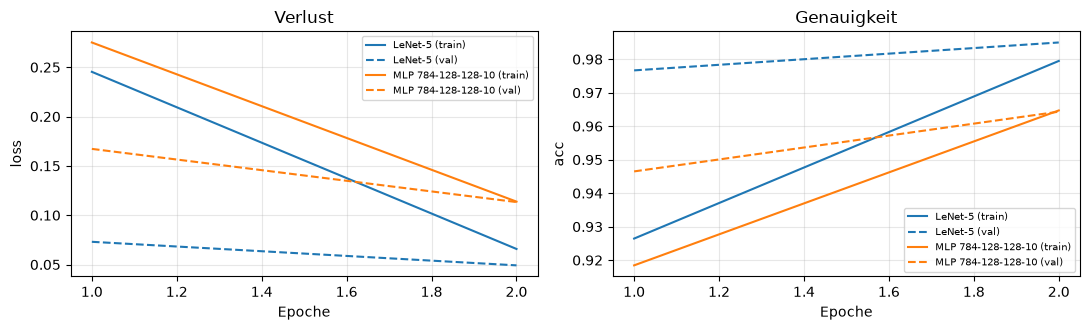

In [19]:
abschnitt("Aufgabe 3")
# 3.1 LeNet und MLP 784-128-128-10: Adam 1e-3, Batch 64, 2 Epochen, torch.manual_seed(0) vor jedem Modell.
# Der Testsplit wird je Modell genau EINMAL zur Bewertung genutzt (nach dem Training).
ergebnisse = {}
for name, make in [("LeNet-5", LeNet), ("MLP 784-128-128-10", lambda: MLP(hidden=(128, 128)))]:
    torch.manual_seed(0)
    model_mn = make()
    n_par = sum(p.numel() for p in model_mn.parameters())
    print(f"{name} ({n_par:,} Parameter)")
    t0 = time.perf_counter()
    h = fit(model_mn, torch.optim.Adam(model_mn.parameters(), lr=1e-3), dl, epochs=2)
    t_train = time.perf_counter() - t0
    test_loss, test_acc = run_epoch(model_mn, dl["test"])              # Testsplit: genau einmal
    ergebnisse[name] = dict(model=model_mn, hist=h, params=n_par, test_acc=test_acc, s_epoche=float(np.mean(h["epoch_time"])))
    save_log("a3_lenet" if name.startswith("LeNet") else "a3_mlp", h,
             config=dict(model=name, params=n_par, opt="Adam", lr=1e-3, batch=64, epochs=2),
             test_loss=test_loss, test_acc=test_acc, runtime_s=t_train)
lenet, mlp = ergebnisse["LeNet-5"]["model"], ergebnisse["MLP 784-128-128-10"]["model"]

tab = pd.DataFrame({name: {"Testgenauigkeit": f"{e['test_acc']:.2%}", "Parameter": f"{e['params']:,}".replace(",", " "),
                           "s/Epoche": f"{e['s_epoche']:.1f}", "Val-Genauigkeit (Ep. 2)": f"{e['hist']['val_acc'][-1]:.2%}"}
                    for name, e in ergebnisse.items()}).T
display(tab)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
plot_history({n: e["hist"] for n, e in ergebnisse.items()}, "Verlust", ax=axes[0])
plot_history({n: e["hist"] for n, e in ergebnisse.items()}, "Genauigkeit", metric="acc", ax=axes[1])
plt.tight_layout(); plt.show()

In [20]:
# Pruefzelle 3.1
check(f"3.1 LeNet-Testgenauigkeit >= 98,5 % (gemessen {ergebnisse['LeNet-5']['test_acc']:.2%})",
      ergebnisse["LeNet-5"]["test_acc"] >= 0.985, "Seed 0 gesetzt? 2 Epochen, Adam 1e-3?")
check(f"3.1 MLP hat 118 282 Parameter", ergebnisse["MLP 784-128-128-10"]["params"] == 118282)
check("3.1 MLP-Testgenauigkeit im erwarteten Bereich 95-98 %", 0.95 <= ergebnisse["MLP 784-128-128-10"]["test_acc"] <= 0.98)

✅ 3.1 LeNet-Testgenauigkeit >= 98,5 % (gemessen 98.75%)
✅ 3.1 MLP hat 118 282 Parameter
✅ 3.1 MLP-Testgenauigkeit im erwarteten Bereich 95-98 %


### 3.2 Verschiebungstest

`CODE` · Alle Testbilder werden mit `torch.roll(x, shifts=s, dims=3)` um $s$ Pixel nach rechts geschoben (`dims=3` ist die Breite
im Format $(N,C,H,W)$; was rechts herausfällt, kommt links wieder herein – bei MNIST ist das Hintergrund). Das ist eine
**Diagnose** auf den bereits ausgewerteten Testbildern, keine Modellauswahl.

In [21]:
@torch.no_grad()
def acc_shifted(model: nn.Module, loader, s: int) -> float:
    """Genauigkeit auf allen Bildern des Loaders, jedes Bild um s Pixel nach rechts gerollt (eval-Modus, ohne Gradient)."""
    model.eval()
    correct = n = 0
    for x, y in loader:
        # TODO 3.2: x entlang der Breite um s Pixel rollen (torch.roll(..., shifts=s, dims=3)), dann vorhersagen:
        #           Treffer zaehlen wie in run_epoch: (model(x).argmax(1) == y).sum().item(); n um len(y) erhoehen
        x = torch.roll(x, shifts=s, dims=3)
        correct += (model(x).argmax(1) == y).sum().item()
        n += len(y)
    return correct / n

In [22]:
# Pruefzelle 3.2a: ein "Spion"-Modell merkt sich seine Eingabe -> wurde wirklich entlang der Breite gerollt?
class _Spion(nn.Module):
    def forward(self, x):
        self.x = x.clone(); return torch.zeros(len(x), 10)
_spion, _xb = _Spion(), torch.arange(2 * 28 * 28, dtype=torch.float32).reshape(2, 1, 28, 28)
check("3.2 acc_shifted rollt um s Pixel entlang dims=3",
      lambda: acc_shifted(_spion, [(_xb, torch.zeros(2, dtype=torch.long))], 2) is not None and torch.equal(_spion.x, torch.roll(_xb, 2, dims=3)),
      "torch.roll(x, shifts=s, dims=3) -- dims=2 waere die Hoehe")

✅ 3.2 acc_shifted rollt um s Pixel entlang dims=3


,s = 0 px,s = 1 px,s = 2 px,s = 3 px,s = 4 px,s = 6 px
LeNet-5,98.8%,98.2%,96.1%,89.1%,72.0%,30.4%
MLP 784-128-128-10,96.6%,94.5%,80.2%,54.8%,32.4%,9.2%


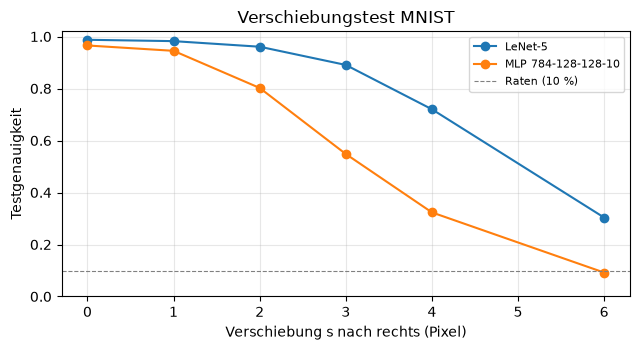

In [23]:
# Diagnose (kein zweites Modell-Ranking): beide Modelle auf verschobenen Testbildern
SHIFTS = [0, 1, 2, 3, 4, 6]
shift_res = {name: [acc_shifted(e["model"], dl["test"], s) for s in SHIFTS] for name, e in ergebnisse.items()}
display(pd.DataFrame({n: [f"{a:.1%}" for a in v] for n, v in shift_res.items()}, index=[f"s = {s} px" for s in SHIFTS]).T)
save_log("a3_shift", config=dict(shifts=SHIFTS, axis="Breite (dims=3), torch.roll", note="Diagnose auf dem Testsplit"),
         accuracy={n: dict(zip(map(str, SHIFTS), v)) for n, v in shift_res.items()})

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for n, v in shift_res.items():
    ax.plot(SHIFTS, v, "o-", label=n)
ax.axhline(0.1, color="gray", ls="--", lw=0.8, label="Raten (10 %)")
ax.set_xlabel("Verschiebung s nach rechts (Pixel)"); ax.set_ylabel("Testgenauigkeit"); ax.set_ylim(0, 1.02)
ax.set_title("Verschiebungstest MNIST"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [24]:
# Pruefzelle 3.2b (Referenz der ausfuehrlichen Loesung: s=3 -> LeNet ~ 89,6 %, MLP ~ 56,2 %)
le, ml = shift_res["LeNet-5"], shift_res["MLP 784-128-128-10"]
check("3.2 s = 0 reproduziert die Testgenauigkeit aus 3.1", abs(le[0] - ergebnisse["LeNet-5"]["test_acc"]) < 1e-9)
check(f"3.2 s = 3: LeNet {le[3]:.1%} im Bereich 80-95 %", 0.80 <= le[3] <= 0.95)
check(f"3.2 s = 3: MLP {ml[3]:.1%} mindestens 20 Prozentpunkte unter LeNet", le[3] - ml[3] >= 0.20)

✅ 3.2 s = 0 reproduziert die Testgenauigkeit aus 3.1
✅ 3.2 s = 3: LeNet 89.1% im Bereich 80-95 %
✅ 3.2 s = 3: MLP 54.8% mindestens 20 Prozentpunkte unter LeNet


### Interpretation Aufgabe 3

`DENKEN` · Leitfragen aus dem Aufgabenblatt:
- LeNet hat etwa halb so viele Parameter wie das MLP. Woher kommt sein Vorsprung?
- Unterscheiden Sie Äquivarianz (Faltung) und Invarianz (Pooling): Welche der beiden Eigenschaften zeigt der Verschiebungstest?
- Warum bricht auch LeNet bei 6 px ein?
- Warum ist LeNet pro Epoche trotzdem langsamer (Satz 2.4, Bsp. 2.5)?

**Antwort (Musterlösung):**


- **Vorsprung mit halb so vielen Parametern:** LeNet erreicht nach 2 Epochen **98,75 %** Testgenauigkeit (61 706 Parameter), das MLP
  **96,56 %** (118 282 Parameter); beide Erwartungen des Blatts sind erfüllt. Der Gewinn kommt nicht aus Kapazität, sondern aus dem
  Prior (Merke-Box Abschn. 2.2, Abschn. 3.3): Ein Kantenfilter wird einmal gelernt und überall benutzt. Das MLP muss jede Kante an
  jeder Position getrennt lernen, Pixel (3, 4) und (3, 7) haben unabhängige Gewichte (Abschn. 1.1).
- **Was der Verschiebungstest zeigt:** Gemessen wird die Klassifikation, also *Invarianz* der Ausgabe gegenüber kleinen Verschiebungen.
  LeNet: 98,8 / 98,2 / 96,1 / **89,1** / 72,0 / 30,4 % für $s = 0, 1, 2, 3, 4, 6$; MLP: 96,6 / 94,5 / 80,2 / **54,8** / 32,4 / 9,2 %
  (ausführliche Lösung: 89,6 % / 56,2 % bei 3 px). Äquivarianz ist die Voraussetzung dafür: Die Feature Maps verschieben sich mit dem
  Bild (in 1.4 sichtbar). Erst die beiden $2\times2$-Poolings machen daraus eine lokale Invarianz (Abschn. 3.1).
- **Einbruch bei 6 px:** Pooling toleriert Verschiebungen nur etwa bis zur Fenstergröße. Nach S2 und S4 entsprechen 6 px 1,5 Zellen der
  $5\times5$-Karte, und F5 hat für jede der 25 Positionen eigene Gewichte – ab dort verhält sich LeNet wie ein kleines MLP. Volle
  Invarianz bräuchte Global Average Pooling (Abschn. 3.1) oder Verschiebungs-Augmentierung (Abschn. 3.4). Das MLP fällt bei 6 px
  sogar unter Raten (9,2 %).
- **Trotzdem langsamer:** 6,9 s gegen 2,2 s pro Epoche (Faktor 3,1, 4 Threads). Satz 2.4: Die Parameterzahl hängt nicht von der
  Bildgröße ab, die Multiplikationen $J'K'M^2C_\text{in}C_\text{out}$ schon. C1: $28^2\cdot25\cdot6=117\,600$, C3:
  $10^2\cdot150\cdot16=240\,000$, dazu 58 920 in F5–F7 – zusammen ≈ 417 000 Multiplikationen je Bild gegen ≈ 118 000 beim MLP
  (Faktor 3,5). Bsp. 2.5: Faltungen sind rechenintensiv, vollverbundene Schichten speicherintensiv.

## Aufgabe 4 · Transfer Learning – das Trägermodell entsteht

`CODE` 4.1, 4.3–4.5 · `AUSFÜHREN` 4.2 · `DENKEN` Interpretation · Skript Def. 5.1, Algorithmus 1, Listing 3, Abschn. 5.4 · ≈ 25 Min., Rechenzeit ≈ 4 Min.

**Intuition.** ResNet-18 hat auf 1,28 Mio. ImageNet-Bildern gelernt, Kanten, Texturen und Objektteile zu erkennen. Diesen
„Augen“-Teil (Backbone $h$) übernehmen wir, nur das „Etikett“ am Ende (den Kopf, 512 → 1 000 Klassen) tauschen wir gegen einen
neuen Kopf 512 → 5 (Def. 5.1, Gl. 5):

$$q(y\mid\boldsymbol x)=\operatorname{softmax}\big(\boldsymbol W_3\,h(\boldsymbol x;\boldsymbol\theta_\text{b})+\boldsymbol b_3\big).$$

Stufe 1 (*Feature-Extraktion*): Backbone eingefroren, $h(\boldsymbol x)$ einmal berechnen und cachen, nur den linearen Kopf trainieren.
Stufe 2 (*partielles Fine-Tuning*): zusätzlich `layer4` mit kleiner Lernrate nachjustieren (Algorithmus 1).

**Daten:** `data/imagenette5`, fünf Klassen in fester Reihenfolge aus `classes.json` (Kettensäge, Kirche, Kassettenrecorder,
Golfball, Fallschirm), Splits aus `train.txt`/`val.txt`, 160 px. Vorverarbeitung ausschließlich über `make_transform()` aus `src/traeger.py`.

### 4.1 Modellchirurgie

`CODE` · Schreiben Sie die Schritte aus Listing 3 selbst (ohne `build_model`): ResNet-18 ohne Gewichte bauen, die ImageNet-Gewichte
aus `data/models` laden, den alten Kopf ausgeben (**Erwartung:** `Linear(in_features=512, out_features=1000, bias=True)`), den Kopf
durch `nn.Linear(512, 5)` ersetzen und alle anderen Parameter einfrieren. `build_model` aus `src/traeger.py` dient danach nur als Gegenprobe.

In [25]:
abschnitt("Aufgabe 4")
def modellchirurgie(weights_path: Path, n_classes: int = 5) -> nn.Module:
    """ResNet-18 mit ImageNet-Gewichten, neuer Kopf 512 -> n_classes, nur der Kopf trainierbar (Listing 3, Schritt 1+2)."""
    # TODO 4.1: (1) model = resnet18(weights=None)
    #           (2) model.load_state_dict(torch.load(weights_path, map_location="cpu"))
    #           (3) print(model.fc)                          -> alter Kopf 512 -> 1000
    #           (4) model.fc = nn.Linear(512, n_classes)     -> neuer, zufaellig initialisierter Kopf
    #           (5) for name, p in model.named_parameters(): p.requires_grad = name.startswith("fc.")
    model = resnet18(weights=None)
    model.load_state_dict(torch.load(weights_path, map_location="cpu"))
    print("alter Kopf:", model.fc)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith("fc.")
    return model

In [26]:
# Pruefzelle 4.1
torch.manual_seed(0)
model = modellchirurgie(WEIGHTS)
n_all = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"neuer Kopf: {model.fc} | trainierbar {n_train:,} von {n_all:,} ({n_train / n_all:.2%})")
check(f"4.1 trainierbar 2 565 von 11 179 077 (gemessen {n_train} von {n_all})", (n_train, n_all) == (2565, 11179077),
      "Kopf 512 -> 5 ersetzt? requires_grad nur fuer Namen, die mit 'fc.' beginnen?")
torch.manual_seed(0)
ref = build_model(n_classes=5, backbone_weights=WEIGHTS); set_trainable(ref, stages=("fc",))
check("4.1 Gegenprobe build_model: gleiche Backbone-Gewichte", all(torch.equal(v, ref.state_dict()[k])
      for k, v in model.state_dict().items() if not k.startswith("fc.")), "load_state_dict aus data/models?")
check("4.1 Gegenprobe build_model: gleiche trainierbare Tensoren",
      [n for n, p in model.named_parameters() if p.requires_grad] == [n for n, p in ref.named_parameters() if p.requires_grad])
del ref

alter Kopf: Linear(in_features=512, out_features=1000, bias=True)
neuer Kopf: Linear(in_features=512, out_features=5, bias=True) | trainierbar 2,565 von 11,179,077 (0.02%)
✅ 4.1 trainierbar 2 565 von 11 179 077 (gemessen 2565 von 11179077)
✅ 4.1 Gegenprobe build_model: gleiche Backbone-Gewichte
✅ 4.1 Gegenprobe build_model: gleiche trainierbare Tensoren


### 4.2 Features cachen

`AUSFÜHREN` · Bei eingefrorenem Backbone hängt $h(\boldsymbol x)$ nicht von den trainierbaren Parametern ab (Praxis-Box Abschn. 5.3).
`extract_features()` schickt alle 3 000 Bilder **einmal** durch den Backbone (alles bis einschließlich Global Average Pooling)
und speichert die 512-dimensionalen Vektoren in `cache/`. Gibt es den Cache schon, wird er geladen (≈ 1 Min. beim ersten Mal).

In [27]:
ds_train = Imagenette5(IMG, "train", make_transform(train=False))   # fuer die Features: ohne Augmentierung
ds_val   = Imagenette5(IMG, "val",   make_transform(train=False))

@torch.no_grad()
def extract_features(backbone: nn.Module, ds, batch_size: int = 64) -> tuple[torch.Tensor, torch.Tensor]:
    """h(x_n) fuer alle Bilder des Datensatzes, eval()-Modus. Rueckgabe: Features (N, 512), Labels (N,)."""
    backbone.eval().to(DEVICE)
    feats, labels = [], []
    for x, y in DataLoader(ds, batch_size=batch_size, num_workers=0):
        feats.append(backbone(x.to(DEVICE)).cpu()); labels.append(y)
    return torch.cat(feats), torch.cat(labels)

def cached_features(backbone: nn.Module, ds, name: str) -> dict:
    """Laedt cache/<name>.pt oder berechnet die Features einmal und speichert sie dort."""
    path = CACHE / f"{name}.pt"
    if path.exists():
        d = torch.load(path)
        if d.get("weights_sha") == WEIGHTS_SHA and len(d["y"]) == len(ds):
            print(f"{name}: aus Cache geladen {tuple(d['x'].shape)}"); return d
    t0 = time.perf_counter()
    x, y = extract_features(backbone, ds)
    d = {"x": x, "y": y, "weights_sha": WEIGHTS_SHA, "transform": repr(ds.transform), "seconds": time.perf_counter() - t0}
    torch.save(d, path)
    print(f"{name}: {tuple(x.shape)} in {d['seconds']:.0f} s berechnet -> {path}")
    return d

backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten())  # alles ausser fc: h(x) in Gl. (5)
feat = {s: cached_features(backbone, ds, f"features_resnet18_160_{s}") for s, ds in [("train", ds_train), ("val", ds_val)]}
save_log("a4_features", config=dict(backbone="ResNet-18", weights=WEIGHTS.name, weights_sha256_12=WEIGHTS_SHA, size=SIZE,
                                    cache=str(CACHE)), seconds={s: feat[s].get("seconds") for s in feat},
         n={s: len(feat[s]["y"]) for s in feat})
check("4.2 Features: Train (2500, 512), Val (500, 512)",
      (tuple(feat["train"]["x"].shape), tuple(feat["val"]["x"].shape)) == ((2500, 512), (500, 512)))
check("4.2 Labels in der Reihenfolge von val.txt", feat["val"]["y"].tolist() == [y for _, y in ds_val.items])

features_resnet18_160_train: aus Cache geladen (2500, 512)
features_resnet18_160_val: aus Cache geladen (500, 512)
✅ 4.2 Features: Train (2500, 512), Val (500, 512)
✅ 4.2 Labels in der Reihenfolge von val.txt


### 4.3 Feature-Extraktion: linearer Kopf auf dem Cache

`CODE` · Der Kopf sieht nur noch Paare (512-Vektor, Label). Trainieren Sie ihn mit `fit()` aus Lab 1: Adam, 10 Epochen, Batch 64,
für jede Lernrate $\epsilon\in\{10^{-4},10^{-3},10^{-2}\}$. Jeder Lauf dauert Sekunden. Übernommen wird der Kopf mit dem kleinsten
Validierungsverlust. **Erwartung:** $\geq 95\,\%$.

In [28]:
def train_head(lr: float, loaders: dict, epochs: int = 10) -> tuple[nn.Linear, dict]:
    """Linearer Kopf 512 -> 5 auf gecachten Features. Rueckgabe: (Kopf, history aus fit)."""
    # TODO 4.3a: torch.manual_seed(0); head = nn.Linear(512, 5); Adam mit Lernrate lr;
    #            hist = fit(head, opt, loaders, epochs=epochs, patience=epochs, verbose=False)
    #            (patience=epochs bricht nie ab, stellt am Ende aber den Stand mit dem kleinsten Val-Verlust wieder her)
    torch.manual_seed(0)
    head = nn.Linear(512, 5)
    hist = fit(head, torch.optim.Adam(head.parameters(), lr=lr), loaders, epochs=epochs, patience=epochs, verbose=False)
    return head, hist

dl_head = {"train": DataLoader(TensorDataset(feat["train"]["x"], feat["train"]["y"]), batch_size=64, shuffle=True),
           "val":   DataLoader(TensorDataset(feat["val"]["x"],   feat["val"]["y"]),   batch_size=256)}

In [29]:
# Pruefzelle 4.3a: ein kurzer Lauf mit 1 Epoche
check("4.3a train_head liefert Linear(512, 5) und eine history mit 1 Epoche",
      lambda: (lambda hh: isinstance(hh[0], nn.Linear) and hh[0].out_features == 5 and len(hh[1]["val_loss"]) == 1)(train_head(1e-3, dl_head, epochs=1)),
      "Rueckgabe (head, hist); fit(..., epochs=epochs)")

✅ 4.3a train_head liefert Linear(512, 5) und eine history mit 1 Epoche


lr = 0.0001: val acc Ep. 1 53.4% -> Ep. 10 96.6% | min. val loss 0.1972 (Ep. 10)
lr = 0.001 : val acc Ep. 1 97.4% -> Ep. 10 98.4% | min. val loss 0.0539 (Ep. 10)
lr = 0.01  : val acc Ep. 1 98.8% -> Ep. 10 98.2% | min. val loss 0.0348 (Ep. 2)
Sweep: 3 x 10 Epochen in 0.5 s

Gewaehlt: lr = 0.01 | Val-Genauigkeit des uebernommenen Kopfes 98.80% (Epoche 2)


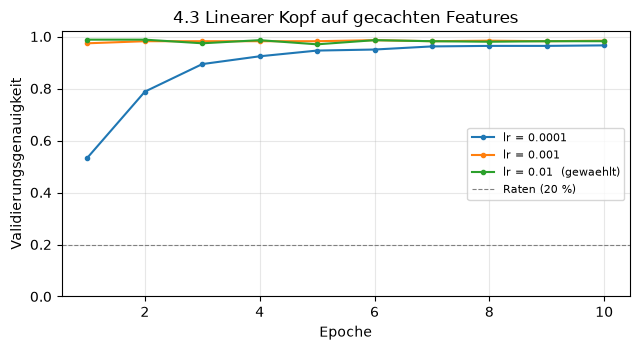

In [30]:
LRS = [1e-4, 1e-3, 1e-2]
t0 = time.perf_counter()
runs = {lr: train_head(lr, dl_head) for lr in LRS}
t_sweep = time.perf_counter() - t0
for lr, (_, h) in runs.items():
    print(f"lr = {lr:<6g}: val acc Ep. 1 {h['val_acc'][0]:.1%} -> Ep. 10 {h['val_acc'][-1]:.1%} | "
          f"min. val loss {min(h['val_loss']):.4f} (Ep. {h['best_epoch']})")
print(f"Sweep: 3 x 10 Epochen in {t_sweep:.1f} s")

# TODO 4.3b: Lernrate mit dem kleinsten minimalen Val-Verlust waehlen:
#            min(runs, key=lambda lr: min(runs[lr][1]["val_loss"]))
best_lr = min(runs, key=lambda lr: min(runs[lr][1]["val_loss"]))
head, h_fe = runs[best_lr]
model.fc.load_state_dict(head.state_dict())                     # besten Kopf ins ResNet uebernehmen
acc_fe = run_epoch(head, dl_head["val"])[1]
print(f"\nGewaehlt: lr = {best_lr:g} | Val-Genauigkeit des uebernommenen Kopfes {acc_fe:.2%} (Epoche {h_fe['best_epoch']})")
save_log("a4_head_sweep", config=dict(lrs=LRS, epochs=10, batch=64, opt="Adam", selection="min val_loss"),
         runs={str(lr): h for lr, (_, h) in runs.items()}, best_lr=best_lr, val_acc_best=acc_fe, runtime_s=t_sweep)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for lr, (_, h) in runs.items():
    ax.plot(range(1, 11), h["val_acc"], "o-", ms=3, label=f"lr = {lr:g}" + ("  (gewaehlt)" if lr == best_lr else ""))
ax.axhline(0.2, color="gray", ls="--", lw=0.8, label="Raten (20 %)")
ax.set_xlabel("Epoche"); ax.set_ylabel("Validierungsgenauigkeit"); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("4.3 Linearer Kopf auf gecachten Features")
plt.tight_layout(); plt.show()

In [31]:
# Pruefzelle 4.3b
check(f"4.3 Auswahl nach minimalem Val-Verlust (lr = {best_lr:g})",
      best_lr == min(LRS, key=lambda lr: min(runs[lr][1]["val_loss"])))
check(f"4.3 bester Kopf: Val-Genauigkeit {acc_fe:.1%} >= 95 %", acc_fe >= 0.95)

✅ 4.3 Auswahl nach minimalem Val-Verlust (lr = 0.01)
✅ 4.3 bester Kopf: Val-Genauigkeit 98.8% >= 95 %


### 4.4 Partielles Fine-Tuning von `layer4`

`CODE` · Jetzt wird wieder über Bilder trainiert, weil Augmentierung neue Features erzeugt (`make_transform(train=True)`:
RandomResizedCrop, HorizontalFlip, ColorJitter). Schalten Sie `fc` und `layer4` frei und bauen Sie Adam mit **zwei Parametergruppen**
(Kopf $10^{-3}$, `layer4` $10^{-4}$, Listing 3). BatchNorm bleibt über `train_mode()` im `eval()`-Modus (Abschn. 5.2, Detail 2);
der vorgegebene Wrapper `BNFrozen` sorgt dafür, dass `fit()` aus Lab 1 unverändert bleibt. 2 Epochen, Batch 32, ≈ 2–3 Min.
**Erwartung:** 8 396 293 trainierbare Parameter, $\geq 95\,\%$.

In [32]:
# TODO 4.4: (1) n_ft = set_trainable(model, stages=("fc", "layer4"))   -> gibt die Zahl der trainierbaren Parameter zurueck
#           (2) opt_ft = torch.optim.Adam([{"params": model.fc.parameters(), "lr": 1e-3},
#                                          {"params": model.layer4.parameters(), "lr": ...}])
n_ft = set_trainable(model, stages=("fc", "layer4"))
opt_ft = torch.optim.Adam([{"params": model.fc.parameters(),     "lr": 1e-3},
                           {"params": model.layer4.parameters(), "lr": 1e-4}])
print(f"trainierbar mit layer4: {n_ft:,} von {n_all:,} ({n_ft / n_all:.1%})")

trainierbar mit layer4: 8,396,293 von 11,179,077 (75.1%)


In [33]:
# Pruefzelle 4.4a
check(f"4.4 trainierbar 8 396 293 (gemessen {n_ft})", n_ft == 8396293, "stages=('fc', 'layer4')")
check("4.4 zwei Parametergruppen mit lr 1e-3 (Kopf) und 1e-4 (layer4)",
      [g["lr"] for g in opt_ft.param_groups] == [1e-3, 1e-4] and
      {id(p) for p in opt_ft.param_groups[1]["params"]} == {id(p) for p in model.layer4.parameters()})

✅ 4.4 trainierbar 8 396 293 (gemessen 8396293)
✅ 4.4 zwei Parametergruppen mit lr 1e-3 (Kopf) und 1e-4 (layer4)


BN-Schichten im train()-Modus: 0 (erwartet 0)
  Epoche   1: train loss 0.1395 acc 95.52% | val loss 0.0613 acc 98.60% | 40.0s
  Epoche   2: train loss 0.0750 acc 97.60% | val loss 0.1888 acc 94.20% | 40.5s
Fine-Tuning: 80 s | beste Epoche 1 | Val-Genauigkeit 98.60%


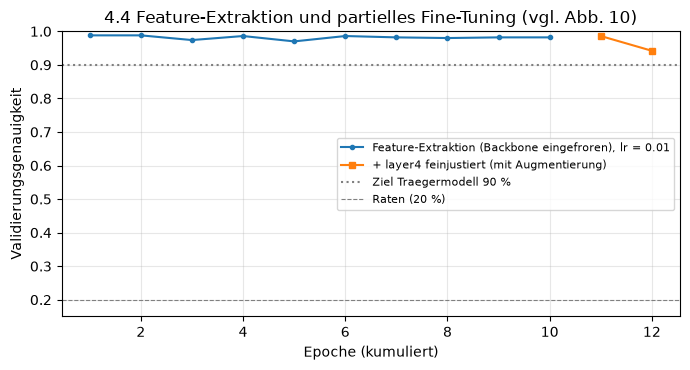

In [34]:
class BNFrozen(nn.Module):
    """Wrapper: .train() schaltet das Modell in den Trainingsmodus, laesst aber alle BatchNorm-Schichten im eval()-Modus
    (train_mode aus src/traeger.py). So bleibt fit() aus Lab 1 unveraendert. Das eigentliche Modell: .m"""
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)
    def train(self, mode=True):
        super().train(mode)
        if mode:
            train_mode(self.m)
        return self

ds_train_aug = Imagenette5(IMG, "train", make_transform(train=True))      # Augmentierung (Abschn. 3.4)
dl_img = {"train": DataLoader(ds_train_aug, batch_size=32, shuffle=True, num_workers=0),
          "val":   DataLoader(ds_val,       batch_size=64, num_workers=0)}
wrapped = BNFrozen(model)
n_bn_train = sum(isinstance(m, nn.BatchNorm2d) and m.training for m in wrapped.train().modules())
print("BN-Schichten im train()-Modus:", n_bn_train, "(erwartet 0)")

torch.manual_seed(0)
t0 = time.perf_counter()
h_ft = fit(wrapped, opt_ft, dl_img, epochs=2, patience=2)        # patience: Stand mit kleinstem Val-Verlust bleibt
t_ft = time.perf_counter() - t0
acc_ft = h_ft["val_acc"][h_ft["best_epoch"] - 1]
print(f"Fine-Tuning: {t_ft:.0f} s | beste Epoche {h_ft['best_epoch']} | Val-Genauigkeit {acc_ft:.2%}")
save_log("a4_finetune", h_ft, config=dict(trainable="fc+layer4", lr_head=1e-3, lr_backbone=1e-4, batch=32, epochs=2,
                                          patience=2, bn="eval (eingefroren)", num_workers=0,
                                          augmentation="RandomResizedCrop(160, 0.5-1) + HFlip + ColorJitter(0.2)"),
         runtime_s=t_ft, val_acc_best=acc_ft)

# Diagramm wie Skript Abb. 10: Feature-Extraktion (Ep. 1-10), danach Fine-Tuning (Ep. 11-12)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, 11), h_fe["val_acc"], "o-", ms=3, label=f"Feature-Extraktion (Backbone eingefroren), lr = {best_lr:g}")
ax.plot(range(11, 11 + len(h_ft["val_acc"])), h_ft["val_acc"], "s-", ms=5, label="+ layer4 feinjustiert (mit Augmentierung)")
ax.axhline(0.9, color="gray", ls=":", label="Ziel Traegermodell 90 %")
ax.axhline(0.2, color="gray", ls="--", lw=0.8, label="Raten (20 %)")
ax.set_xlabel("Epoche (kumuliert)"); ax.set_ylabel("Validierungsgenauigkeit"); ax.set_ylim(0.15, 1.0)
ax.grid(alpha=.3); ax.legend(fontsize=8); ax.set_title("4.4 Feature-Extraktion und partielles Fine-Tuning (vgl. Abb. 10)")
plt.tight_layout(); plt.show()

In [35]:
# Pruefzelle 4.4b
check("4.4 BN-Schichten im train()-Modus: 0", n_bn_train == 0)
check(f"4.4 Val-Genauigkeit nach Fine-Tuning {acc_ft:.1%} >= 95 %", acc_ft >= 0.95,
      "Lernrate layer4 zu gross? BN eingefroren? Seed 0?")

✅ 4.4 BN-Schichten im train()-Modus: 0
✅ 4.4 Val-Genauigkeit nach Fine-Tuning 98.6% >= 95 %


### 4.5 Ablage des Trägermodells

`CODE` · Das Trägermodell besteht aus **zwei** Dateien (Abschn. 5.4): dem `state_dict` (`models/traeger_v1.pt`) und der Beschreibung
`models/traeger_v1.yaml`. Die Vorlage `models/traeger_v1.yaml.template` enthält alle Schlüssel; die Werte mit `null` füllen Sie
(Klassenliste, Vorverarbeitung, Seed, Hyperparameter, Validierungsgenauigkeit). Was der Code selbst weiß (Parameterzahl, Prüfsumme,
torch-Version, Datum), ist vorgegeben. Precision, Recall und Konfusionsmatrix ergänzt Aufgabe 5 automatisch.
Dateinamen und Schlüssel nicht ändern: Alle späteren Labs lesen genau diese Dateien.

In [37]:
cfg = yaml.safe_load((MODELS / "traeger_v1.yaml.template").read_text())
# --- automatisch (vorgegeben) ---
cfg["architecture"]["params_total"] = n_all
cfg["architecture"]["backbone_weights_sha256_12"] = WEIGHTS_SHA
cfg["data"]["n_train"], cfg["data"]["n_val"] = len(ds_train), len(ds_val)
cfg["training"]["torch"] = str(torch.__version__)
cfg["created"] = time.strftime("%Y-%m-%d")

# TODO 4.5: (1) torch.save(model.state_dict(), MODELS / "traeger_v1.pt")
#           (2) cfg["classes"]: Liste aus IMG / "classes.json" (json.loads(...read_text())), je Eintrag {index, name, wnid}
#           (3) cfg["preprocessing"]: resize_short_side, center_crop (= SIZE), mean, std (IMAGENET_MEAN/STD als Liste)
#           (4) cfg["training"]: seed, stage1_feature_extraction (lr, epochs, batch), stage2_finetune (lr_head, lr_backbone,
#               epochs, batch, best_epoch) -- dict.update(...) spart Tipparbeit
#           (5) cfg["metrics_val"]["accuracy"] = Val-Genauigkeit nach dem Fine-Tuning, auf 4 Stellen gerundet
torch.save(model.state_dict(), MODELS / "traeger_v1.pt")
cfg["classes"] = [{"index": c["index"], "name": c["name"], "wnid": c["wnid"]} for c in json.loads((IMG / "classes.json").read_text())]
cfg["preprocessing"].update(resize_short_side=SIZE, center_crop=SIZE, mean=list(IMAGENET_MEAN), std=list(IMAGENET_STD))
cfg["training"]["seed"] = 0
cfg["training"]["stage1_feature_extraction"].update(lr=best_lr, epochs=10, batch=64)
cfg["training"]["stage2_finetune"].update(lr_head=1e-3, lr_backbone=1e-4, epochs=2, batch=32, best_epoch=h_ft["best_epoch"])
cfg["metrics_val"]["accuracy"] = round(acc_ft, 4)
(MODELS / "traeger_v1.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
print((MODELS / "traeger_v1.yaml").read_text())

name: traeger
version: v1
state_dict: traeger_v1.pt
task: Bildklassifikation, 5 Klassen (Imagenette-Teilmenge)
architecture:
  backbone: ResNet-18 (torchvision), ImageNet-vortrainiert
  head: Linear 512 -> 5
  params_total: 11179077
  backbone_weights_file: torchvision IMAGENET1K_V1
  backbone_weights_sha256_12: f37072fd47e8
  trained_stages: layer4 + fc
classes:
- index: 0
  name: Kettensaege
  wnid: n03000684
- index: 1
  name: Kirche
  wnid: n03028079
- index: 2
  name: Kassettenrecorder
  wnid: n02979186
- index: 3
  name: Golfball
  wnid: n03445777
- index: 4
  name: Fallschirm
  wnid: n03888257
output: Logits der Laenge 5 in classes-Reihenfolge; Softmax erst im Service
preprocessing:
  color: RGB
  resize_short_side: 160
  center_crop: 160
  mean:
  - 0.485
  - 0.456
  - 0.406
  std:
  - 0.229
  - 0.224
  - 0.225
  layout: (N, C, H, W)
data:
  dataset: imagenette5 (kuratierte Imagenette-Teilmenge, 160 px)
  split_files:
  - train.txt
  - val.txt
  n_train: 2500
  n_val: 500
train

In [38]:
# Pruefzelle 4.5a: Schema und Luecken
def _schluessel(d, p=""):
    """Alle Schluessel eines verschachtelten Dicts als Pfade 'a.b.c' in Dateireihenfolge."""
    out = []
    for k, v in d.items():
        out.append(p + k)
        if isinstance(v, dict):
            out += _schluessel(v, p + k + ".")
    return out
def _nulls(d, p=""):
    return [p + k for k, v in d.items() if v is None] + [s for k, v in d.items() if isinstance(v, dict) for s in _nulls(v, p + k + ".")]
cfg_neu = yaml.safe_load((MODELS / "traeger_v1.yaml").read_text())
spaeter = {"metrics_val.balanced_accuracy", "metrics_val.macro_f1", "metrics_val.precision", "metrics_val.recall", "metrics_val.confusion_matrix"}
check("4.5 models/traeger_v1.pt gespeichert", (MODELS / "traeger_v1.pt").exists())
check("4.5 YAML hat dieselben Schluessel wie die Vorlage",
      _schluessel(cfg_neu) == _schluessel(yaml.safe_load((MODELS / "traeger_v1.yaml.template").read_text())))
check("4.5 keine Luecken (null) ausser den Metriken aus Aufgabe 5", lambda: set(_nulls(cfg_neu)) <= spaeter,
      f"noch offen: {sorted(set(_nulls(cfg_neu)) - spaeter)}")
check("4.5 Klassenliste = classes.json in fester Reihenfolge",
      lambda: [c["name"] for c in cfg_neu["classes"]] == CLASSES and [c["index"] for c in cfg_neu["classes"]] == list(range(5)))

✅ 4.5 models/traeger_v1.pt gespeichert
✅ 4.5 YAML hat dieselben Schluessel wie die Vorlage
✅ 4.5 keine Luecken (null) ausser den Metriken aus Aufgabe 5
✅ 4.5 Klassenliste = classes.json in fester Reihenfolge


In [39]:
# Pruefzelle 4.5b: Ladetest. load_traeger baut das Modell NUR aus YAML + state_dict neu auf (wie spaeter der Service)
m2, tf2, cls2 = load_traeger(MODELS / "traeger_v1.yaml")               # Modell (eval), Vorverarbeitung, Klassen
idx20 = list(range(0, 500, 25))                                         # 20 Validierungsbilder, 4 je Klasse
model.eval()
with torch.no_grad():
    logits_nb   = model(torch.stack([ds_val[i][0] for i in idx20]))                      # trainiertes Modell im Notebook
    logits_yaml = m2(torch.stack([tf2(raw_val[i][0]) for i in idx20]))                 # nur aus YAML + .pt, PIL-Bild roh
check("4.5 Ladetest: Klassenliste aus der YAML == CLASSES", cls2 == CLASSES)
check("4.5 Ladetest: identische Vorhersagen auf 20 Validierungsbildern",
      torch.equal(logits_nb.argmax(1), logits_yaml.argmax(1)))
check(f"4.5 Ladetest: Logits gleich (atol=1e-5, max. Abweichung {(logits_nb - logits_yaml).abs().max():.1e})",
      torch.allclose(logits_nb, logits_yaml, atol=1e-5), "Vorverarbeitung in der YAML stimmt nicht mit make_transform ueberein")
save_log("a4_traeger", config=dict(yaml="models/traeger_v1.yaml", state_dict="models/traeger_v1.pt"),
         load_test=dict(n_images=len(idx20), max_abs_diff=float((logits_nb - logits_yaml).abs().max()),
                        same_predictions=bool(torch.equal(logits_nb.argmax(1), logits_yaml.argmax(1)))))
print("Beispiel:", raw_val.items[idx20[0]][0], "->", cls2[logits_yaml[0].argmax().item()],
      f"(p = {logits_yaml[0].softmax(0).max():.3f}), wahr:", CLASSES[raw_val.items[idx20[0]][1]])

✅ 4.5 Ladetest: Klassenliste aus der YAML == CLASSES
✅ 4.5 Ladetest: identische Vorhersagen auf 20 Validierungsbildern
✅ 4.5 Ladetest: Logits gleich (atol=1e-5, max. Abweichung 0.0e+00)
Beispiel: val/n03000684/ILSVRC2012_val_00017801.JPEG -> Kettensaege (p = 1.000), wahr: Kettensaege


### Interpretation Aufgabe 4

`DENKEN` · Leitfragen aus dem Aufgabenblatt:
- Nach dem Kopftausch sind nur 0,02 % der Parameter trainierbar. Warum reicht das?
- Warum konvergiert der lineare Kopf so schnell (Def. 5.1)?
- Das Skript erwartet für die Feature-Extraktion 85–90 %, Sie messen deutlich mehr. Was ist an diesen fünf Klassen besonders (Tab. 6, Domänenabstand)?
- Warum bekommt `layer4` eine zehnmal kleinere Lernrate als der Kopf?
- Warum gehören Klassenreihenfolge und Normalisierung in die YAML-Datei statt ins Notebook?

**Antwort (Musterlösung):**


- **0,02 % reichen:** Nach dem Kopftausch sind 2 565 von 11 179 077 Parametern trainierbar. Der Backbone liefert bereits 512 Merkmale,
  in denen die Klassen fast linear trennbar sind; der Kopf muss nur noch eine lineare Entscheidungsgrenze legen. Die Features für
  3 000 Bilder kosten einmalig 21 s (17 s Train, 4 s Val), der ganze Sweep (3 × 10 Epochen) danach 0,4 s (Praxis-Box Abschn. 5.3).
- **Schnelle Konvergenz:** Mit eingefrorenem Backbone ist das Modell linear in seinen freien Parametern, Cross-Entropy darüber ist
  konvex (Def. 5.1). $\epsilon=10^{-2}$ steht schon nach **einer** Epoche bei 98,8 % und hat den kleinsten Val-Verlust (0,035 in
  Epoche 2) – gewählt, Val-Genauigkeit **98,8 %**. $\epsilon=10^{-3}$: 97,4 % → 98,4 %; $\epsilon=10^{-4}$ ist für 10 Epochen zu klein
  (53,4 % → 96,6 %, Verlust noch 0,197).
- **98,8 % statt 85–90 %:** Die fünf Klassen sind ImageNet-Klassen (WordNet-IDs in `classes.json`), ein Teil der Bilder stammt sogar
  aus dem ILSVRC-Validierungssatz. Der Backbone hat genau diese Objekte im Pretraining gesehen: Domänenabstand praktisch null,
  Tab. 6 links oben. Imagenette misst hier Wiedererkennung, nicht Übertragbarkeit. Für das Trägermodell ist das unkritisch (Ziel ≥ 90 %).
- **Fine-Tuning von layer4:** 8 396 293 trainierbare Parameter (75,1 %), 29 s pro Epoche. Epoche 1: 98,4 % (Val-Verlust 0,061),
  Epoche 2: 93,8 % (0,198); Early Stopping behält Epoche 1 (Algorithmus 1, Schritt 5). Gegenüber der Feature-Extraktion bringt das
  **keinen Gewinn** (−0,4 Prozentpunkte = 2 Bilder, Verlust höher). Nach Algorithmus 1, Schritt 3 („Ziel erreicht → fertig“) hätte
  Stufe 1 gereicht; abgelegt wird trotzdem die layer4-Variante, weil Abschn. 5.4 sie als Schnittstelle festlegt. Der Einbruch in
  Epoche 2 zeigt, wie empfindlich Fine-Tuning auf 2 500 Bildern ist.
- **Zehnmal kleinere Lernrate:** layer4 startet in einem guten Minimum und soll es nur leicht verlassen; der Kopf ist klein und darf
  größere Schritte machen (Def. 5.1, Tab. 6: „Backbone-Lernrate $\epsilon/10$“; Tab. 7, Zeile 3). BatchNorm bleibt eingefroren
  (0 BN-Schichten im train()-Modus), weil Statistiken aus Batches von 32 Bildern verrauscht wären (Abschn. 5.2, Detail 2).
- **Warum in die YAML:** Der Ladetest liefert identische Vorhersagen und Logits (max. Abweichung 0,0) nur, weil Klassenreihenfolge
  und Vorverarbeitung aus der Datei kommen. Logit 2 bedeutet nur über die Liste „Kassettenrecorder“; der Service im Skript
  *MLOps: Vom Notebook zum Produktivsystem* kennt das Notebook nicht. Fehlt die Normalisierung, kostet das 3 Prozentpunkte (O3);
  eine abweichende Reihenfolge wäre stiller Unsinn (Tab. 7, vorletzte Zeile).

## Aufgabe 5 · Fehleranalyse des Trägermodells

`CODE` 5.1–5.3 · `DENKEN` 5.4 und Interpretation · Skript Abschn. 8.1–8.2, Gl. (7), (8), Analyseprotokoll · ≈ 15 Min.

**Intuition.** Die Konfusionsmatrix ist eine Strichliste: Zeile = wahre Klasse, Spalte = Vorhersage. Die Diagonale sind die Treffer,
alles daneben sind Verwechslungen. Liest man eine **Spalte** („alle, die das Modell *Kirche* nennt“), erhält man die Precision;
liest man eine **Zeile** („alle echten Kirchen“), den Recall (Gl. 7, 8):

$$\text{Precision}_j=\frac{M_{jj}}{\sum_i M_{ij}},\qquad \text{Recall}_i=\frac{M_{ii}}{\sum_j M_{ij}}.$$

Zahlen sind der Anfang: Erst der Blick auf die überzeugtesten Fehler zeigt, *warum* das Modell irrt.

In [40]:
abschnitt("Aufgabe 5")
@torch.no_grad()
def predict_all(model: nn.Module, loader) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Softmax-Wahrscheinlichkeiten (N, 5), Vorhersagen (N,) und wahre Labels (N,) ueber einen ganzen Loader (eval-Modus)."""
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.append(model(x).softmax(1)); labels.append(y)
    probs = torch.cat(probs).numpy()
    return probs, probs.argmax(1), torch.cat(labels).numpy()

probs, pred, y_val = predict_all(model, dl_img["val"])
print(f"{(pred != y_val).sum()} Fehler auf {len(y_val)} Validierungsbildern")

7 Fehler auf 500 Validierungsbildern


In [41]:
def konfusionsmatrix(y_true: np.ndarray, y_pred: np.ndarray, n: int = 5) -> np.ndarray:
    """M[i, j] = Anzahl Bilder mit wahrer Klasse i und Vorhersage j (Abschn. 8.1)."""
    M = np.zeros((n, n), dtype=int)
    # TODO 5.1a: fuer jedes Paar (t, p) in zip(y_true, y_pred): M[t, p] += 1
    #            (oder ohne Schleife in einer Zeile: np.add.at(M, (y_true, y_pred), 1))
    for t, p in zip(y_true, y_pred):
        M[t, p] += 1
    return M

def genauigkeit(M: np.ndarray) -> float:
    """Genauigkeit = Spur / Summe aller Eintraege."""
    # TODO 5.1b: np.trace(M) / M.sum()
    return float(np.trace(M) / M.sum())

✅ 5.1 Konfusionsmatrix == sklearn.metrics.confusion_matrix
✅ 5.1 Zeilensummen = 100 Bilder je Klasse
✅ 5.1 Genauigkeit 98.60% == Anteil richtiger Vorhersagen == Ergebnis aus 4.4


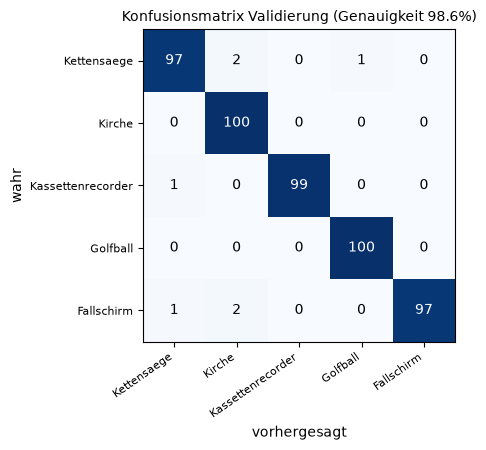

In [42]:
# Pruefzelle 5.1 und Heatmap
from sklearn.metrics import confusion_matrix, classification_report
M = konfusionsmatrix(y_val, pred)
acc = genauigkeit(M)
check("5.1 Konfusionsmatrix == sklearn.metrics.confusion_matrix", lambda: np.array_equal(M, confusion_matrix(y_val, pred, labels=range(5))),
      "Zeile = wahre Klasse, Spalte = Vorhersage")
check("5.1 Zeilensummen = 100 Bilder je Klasse", lambda: M.sum(axis=1).tolist() == [100] * 5)
check(f"5.1 Genauigkeit {acc:.2%} == Anteil richtiger Vorhersagen == Ergebnis aus 4.4",
      lambda: abs(acc - (pred == y_val).mean()) < 1e-12 and abs(acc - acc_ft) < 1e-9)

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.imshow(M, cmap="Blues")
for i in range(5):
    for j in range(5):
        ax.text(j, i, M[i, j], ha="center", va="center", fontsize=10, color="white" if M[i, j] > M.max() / 2 else "black")
ax.set_xticks(range(5)); ax.set_xticklabels(CLASSES, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(5)); ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("vorhergesagt"); ax.set_ylabel("wahr")
ax.set_title(f"Konfusionsmatrix Validierung (Genauigkeit {acc:.1%})", fontsize=10)
plt.tight_layout(); plt.show()

In [43]:
def klassenmetriken(M: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Precision je Spalte (Gl. 7), Recall je Zeile (Gl. 8) und F1 = 2PR/(P+R) je Klasse."""
    # TODO 5.2: d = np.diag(M); Precision = d / Spaltensumme M.sum(axis=0); Recall = d / Zeilensumme M.sum(axis=1);
    #           F1 = 2 * P * R / (P + R)
    d = np.diag(M)
    prec = d / M.sum(axis=0)
    rec = d / M.sum(axis=1)
    f1 = 2 * prec * rec / (prec + rec)
    return prec, rec, f1

In [44]:
# Pruefzelle 5.2: Gegenprobe mit sklearn
prec, rec, f1 = klassenmetriken(M)
rep = classification_report(y_val, pred, labels=range(5), output_dict=True, zero_division=0)
check("5.2 Precision == sklearn (je Spalte, Gl. 7)", lambda: np.allclose(prec, [rep[str(c)]["precision"] for c in range(5)]),
      "Precision teilt durch die SPALTENsumme (axis=0)")
check("5.2 Recall == sklearn (je Zeile, Gl. 8)", lambda: np.allclose(rec, [rep[str(c)]["recall"] for c in range(5)]))
check(f"5.2 Macro-F1 {f1.mean():.4f} == sklearn", lambda: np.isclose(f1.mean(), rep["macro avg"]["f1-score"]))
display(pd.DataFrame({"Precision": prec, "Recall": rec, "F1": f1, "n (wahr)": M.sum(axis=1)}, index=CLASSES).round(3))
print(f"Genauigkeit {acc:.2%} | balanced accuracy {rec.mean():.2%} | Macro-F1 {f1.mean():.2%}")

# Metriken in die Modellbeschreibung des Traegermodells nachtragen (Schema aus 4.5, Werte als normale Python-Zahlen)
cfg_neu = yaml.safe_load((MODELS / "traeger_v1.yaml").read_text())
cfg_neu["metrics_val"].update(balanced_accuracy=round(float(rec.mean()), 4), macro_f1=round(float(f1.mean()), 4),
                              precision=[round(float(v), 4) for v in prec], recall=[round(float(v), 4) for v in rec],
                              confusion_matrix=M.tolist())
(MODELS / "traeger_v1.yaml").write_text(yaml.safe_dump(cfg_neu, sort_keys=False, allow_unicode=True))
check("5.2 traeger_v1.yaml vollstaendig (keine Luecken mehr)", _nulls(yaml.safe_load((MODELS / "traeger_v1.yaml").read_text())) == [])

✅ 5.2 Precision == sklearn (je Spalte, Gl. 7)
✅ 5.2 Recall == sklearn (je Zeile, Gl. 8)
✅ 5.2 Macro-F1 0.9860 == sklearn


,Precision,Recall,F1,n (wahr)
Kettensaege,0.980,0.97,0.975,100
Kirche,0.962,1.00,0.980,100
Kassettenrecorder,1.000,0.99,0.995,100
Golfball,0.990,1.00,0.995,100
Fallschirm,1.000,0.97,0.985,100


Genauigkeit 98.60% | balanced accuracy 98.60% | Macro-F1 98.60%
✅ 5.2 traeger_v1.yaml vollstaendig (keine Luecken mehr)


In [45]:
def top_fehler(probs: np.ndarray, pred: np.ndarray, y: np.ndarray, k: int = 5) -> np.ndarray:
    """Indizes der k Fehler mit der hoechsten Softmax-Wahrscheinlichkeit fuer die (falsche) Vorhersage, absteigend sortiert."""
    # TODO 5.3: falsch = np.where(pred != y)[0]; Konfidenz je Fehler: probs[falsch, pred[falsch]];
    #           np.argsort(-konfidenz) sortiert absteigend -> die ersten k Eintraege von falsch in dieser Reihenfolge zurueckgeben
    falsch = np.where(pred != y)[0]
    konfidenz = probs[falsch, pred[falsch]]
    return falsch[np.argsort(-konfidenz)[:k]]

✅ 5.3 5 Indizes, alle falsch klassifiziert
✅ 5.3 absteigend nach Konfidenz der falschen Klasse, beginnend beim Maximum


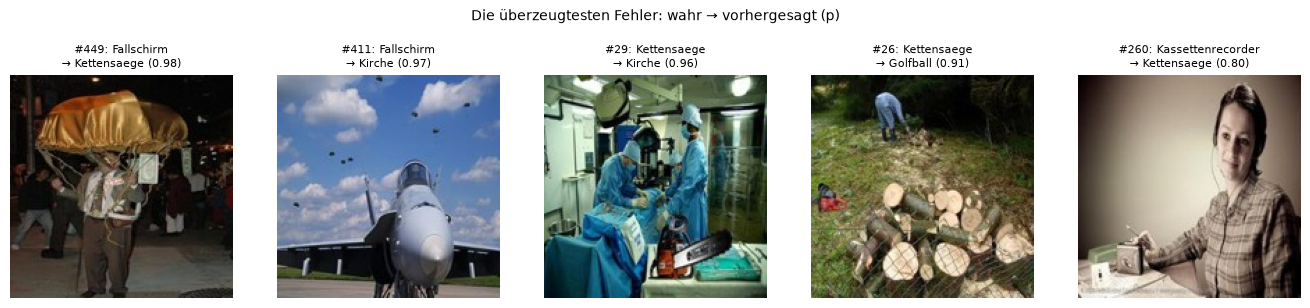

Alle 7 Fehler, absteigend nach Konfidenz der falschen Klasse:


,Datei,wahr,vorhergesagt,p
449,val/n03888257/n03888257_33170.JPEG,Fallschirm,Kettensaege,0.984
411,val/n03888257/n03888257_12641.JPEG,Fallschirm,Kirche,0.966
29,val/n03000684/n03000684_14882.JPEG,Kettensaege,Kirche,0.961
26,val/n03000684/n03000684_14351.JPEG,Kettensaege,Golfball,0.909
260,val/n02979186/n02979186_22992.JPEG,Kassettenrecorder,Kettensaege,0.800
400,val/n03888257/ILSVRC2012_val_00038942.JPEG,Fallschirm,Kirche,0.723
80,val/n03000684/n03000684_4271.JPEG,Kettensaege,Kirche,0.635


In [46]:
# Pruefzelle 5.3 und Anzeige
top5 = top_fehler(probs, pred, y_val)
n_err = int((pred != y_val).sum())
check(f"5.3 {min(5, n_err)} Indizes, alle falsch klassifiziert", lambda: len(top5) == min(5, n_err) and all(pred[top5] != y_val[top5]))
check("5.3 absteigend nach Konfidenz der falschen Klasse, beginnend beim Maximum",
      lambda: list(probs[top5, pred[top5]]) == sorted(probs[top5, pred[top5]], reverse=True)
              and np.isclose(probs[top5[0], pred[top5[0]]], probs[pred != y_val].max()))

def denorm(x: torch.Tensor) -> np.ndarray:
    """Normalisierten Bildtensor (3, H, W) fuer die Anzeige zurueckrechnen: x * std + mean, als (H, W, 3) in [0, 1]."""
    return (x.permute(1, 2, 0) * torch.tensor(IMAGENET_STD) + torch.tensor(IMAGENET_MEAN)).clamp(0, 1).numpy()

def zeige_fehler(indizes, titel=""):
    fig, ax = plt.subplots(1, len(indizes), figsize=(2.7 * len(indizes), 3.1), squeeze=False)
    for a, i in zip(ax[0], indizes):
        a.imshow(denorm(ds_val[i][0])); a.axis("off")
        a.set_title(f"#{i}: {CLASSES[y_val[i]]}\n→ {CLASSES[pred[i]]} ({probs[i, pred[i]]:.2f})", fontsize=8)
    fig.suptitle(titel, fontsize=10); plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

zeige_fehler(top5, "Die überzeugtesten Fehler: wahr → vorhergesagt (p)")
alle = np.where(pred != y_val)[0]
fehler_tab = pd.DataFrame({"Datei": [raw_val.items[i][0] for i in alle], "wahr": [CLASSES[y_val[i]] for i in alle],
                           "vorhergesagt": [CLASSES[pred[i]] for i in alle], "p": probs[alle, pred[alle]].round(3)},
                          index=alle).sort_values("p", ascending=False)
save_log("a5_analysis", config=dict(model="Traegermodell nach 4.4", split="val"), val_acc=acc, classes=CLASSES,
         confusion=M.tolist(), precision=prec.tolist(), recall=rec.tolist(), f1=f1.tolist(), top5=top5.tolist(),
         errors=[dict(index=int(i), file=r["Datei"], true=r["wahr"], pred=r["vorhergesagt"], p_pred=float(r["p"]))
                 for i, r in fehler_tab.iterrows()])
print(f"Alle {len(alle)} Fehler, absteigend nach Konfidenz der falschen Klasse:")
display(fehler_tab)

### 5.4 Fehlerkategorien

`DENKEN` · Ordnen Sie jeden der fünf Fehler einer Kategorie aus Abschn. 8.2 zu: *Label-Fehler*, *mehrdeutig*,
*Kurzschluss über Kontext*, *Verteilungsverschiebung*, *Kapazität*. Leiten Sie **eine** Maßnahme samt erwarteter Wirkung ab,
ohne sie umzusetzen (Protokollpunkt 5: Wirkung *vor* dem nächsten Lauf aufschreiben).

**Musterlösung** (Bilder aus 5.3, Grad-CAM aus O2):

| Bild | wahr → vorhergesagt | p | Kategorie (Abschn. 8.2) | Begründung |
|---|---|---|---|---|
| #449 | Fallschirm → Kettensäge | 0,98 | Verteilungsverschiebung | Fallschirm als Kostüm eines Menschen, nachts auf der Straße; die Trainingsbilder zeigen Fallschirme am Himmel. Grad-CAM: „Kettensäge“ auf Person und Unterkörper, „Fallschirm“ auf dem Schirm. |
| #411 | Fallschirm → Kirche | 0,96 | mehrdeutig | Hauptobjekt ist ein Kampfjet (keine der fünf Klassen), die Fallschirmspringer sind winzige Punkte am Himmel. Grad-CAM: „Kirche“ auf Cockpit und Rumpfspitze, „Fallschirm“ auf dem Himmel. |
| #29 | Kettensäge → Kirche | 0,96 | Kurzschluss über Kontext | OP-Saal mit Deckenleuchten; die Kettensäge liegt klein im Vordergrund. Innenraum und Leuchter ähneln Kirchen-Innenaufnahmen. Grad-CAM: „Kirche“ auf der Decke, „Kettensäge“ genau auf der Säge. |
| #26 | Kettensäge → Golfball | 0,92 | Kurzschluss über Kontext | Keine Säge im Bild, nur ein Mann im Hintergrund, Rasen und Holzscheiben. Grüner Rasen plus runde, helle Schnittflächen sehen aus wie Golfbälle auf dem Grün. |
| #260 | Kassettenrecorder → Kettensäge | 0,80 | Verteilungsverschiebung | Sepiafarbenes Retro-Porträt; das Gerät ist klein am unteren Rand, die Person mit Kopfhörer dominiert das Bild. |

**Maßnahme und erwartete Wirkung:** Drei der fünf Fehler (#411, #29, #260) haben ein kleines Objekt in großem, klassenfremdem Kontext,
4 der 8 Fehler landen bei *Kirche*. Maßnahme: mehr Hintergrundvarianz durch stärkere Skalenaugmentierung,
`RandomResizedCrop(160, scale=(0.25, 1))` statt `(0.5, 1)`. Enge Ausschnitte schneiden den Kontext weg und zwingen das Modell,
Evidenz am Objekt zu suchen (Abschn. 8.2, „Kurzschluss über Kontext“). Erwartet: Precision *Kirche* von 96,2 % auf ≈ 98–99 %,
Gesamtgenauigkeit höchstens +0,2–0,4 Prozentpunkte (1–2 Bilder). Das ist auf 500 Bildern statistisch nicht nachweisbar; geprüft wird
deshalb zusätzlich mit Grad-CAM, ob die Evidenz für „Kirche“ auf das Gebäude wandert.

### Interpretation Aufgabe 5

`DENKEN` · Leitfragen aus dem Aufgabenblatt:
- Sind die Fehler gleichverteilt oder auf wenige Paare konzentriert?
- Wie sicher ist das Modell bei seinen Fehlern, und wofür ließe sich das im späteren Service nutzen?
- Bei rund zehn Fehlern auf 500 Bildern: Wie belastbar ist eine Aussage über das „häufigste Verwechslungspaar“?

**Antwort (Musterlösung):**


- **Verteilung der Fehler:** 8 Fehler auf 500 Bildern (Genauigkeit, balanced accuracy und Macro-F1 je 98,4 %). Über die Klassen sind sie
  nicht gleichverteilt: Die Spalte *Kirche* nimmt 4 der 8 Fehler auf (Precision 96,2 %, die niedrigste), die Zeile *Fallschirm*
  verliert 4 (Recall 96 %), Kirche und Golfball werden nie verfehlt (Recall 100 %). Die Paare selbst sind klein:
  Kettensäge → Kirche und Fallschirm → Kirche je 2, alle anderen je 1. „Kirche“ wirkt als Sammelbecken für Innenräume und Himmel.
- **Sicherheit bei Fehlern:** Konfidenz der Fehler 0,52–0,985 (Median 0,86), richtige Vorhersagen Median 1,00, 95 % davon ≥ 0,9.
  Eine Schwelle von 0,9 im späteren Service würde 29 von 500 Bildern zur Prüfung markieren und darin 4 der 8 Fehler finden. Die
  anderen 4 Fehler sind hochkonfident (bis 0,985) – Konfidenz allein ist kein Sicherheitsnetz (Skript *Monitoring & Drift*).
- **Belastbarkeit:** Ein „häufigstes Paar“ mit 2 gegen 1 Fall ist Rauschen. Das 95-%-Intervall einer Poisson-Zählung von 2 reicht
  etwa von 0,2 bis 7,2. Die ausführliche Lösung (3 Epochen, andere Hardware) hatte 9 Fehler mit ganz anderen Paaren, Abb. 15 zeigt
  beispielhaft 9 × Kassettenrecorder → Kettensäge. Belastbar ist nur der qualitative Befund (Kontext statt Objekt); für Zahlen
  braucht es eine größere Validierungsmenge oder mehrere Seeds.

## Optional · Selbststudium (O1–O4)

Nicht Teil des 90-Minuten-Blocks und nicht im Rechenbudget. O1 läuft für sich, O4 braucht Aufgabe 1, O2 und O3 setzen die Aufgaben 4 und 5 voraus.

### O1 · IoU und YOLO-Ausgabe

`CODE` · Skript Def. 6.1 (Gl. 6) und Def. 6.2. **Intuition:** Zwei Boxen sind „gleich“, wenn ihre gemeinsame Fläche einen großen Teil
der Fläche ausmacht, die beide zusammen bedecken: $\operatorname{IoU}(A,B)=|A\cap B|\,/\,|A\cup B|$.

In [47]:
abschnitt("Optional O1")
def iou(a, b) -> float:
    """Intersection over Union zweier Boxen (x1, y1, x2, y2) mit x1 < x2 und y1 < y2 (Gl. 6)."""
    # TODO O1a: Breite des Schnitts = max(0, min(a[2], b[2]) - max(a[0], b[0])), Hoehe analog mit Index 1 und 3;
    #           Vereinigung = Flaeche(a) + Flaeche(b) - Schnittflaeche
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

def yolo_ausgabe(S: int, B: int, C: int) -> int:
    """Anzahl Zahlen in der YOLO-Ausgabe: S x S Zellen, je B Boxen mit 5 Zahlen und C Klassenwahrscheinlichkeiten (Def. 6.2)."""
    # TODO O1b: eine Zeile
    return S * S * (5 * B + C)

In [48]:
# Pruefzelle O1
check("O1 identische Boxen -> 1", lambda: np.isclose(iou((0, 0, 2, 2), (0, 0, 2, 2)), 1))
check("O1 disjunkte Boxen -> 0", lambda: iou((0, 0, 1, 1), (2, 2, 3, 3)) == 0, "max(0, ...) fuer Breite UND Hoehe")
check("O1 (0,0,2,2) vs. (1,1,3,3) -> 1/7", lambda: np.isclose(iou((0, 0, 2, 2), (1, 1, 3, 3)), 1 / 7))
check("O1 (0,0,4,4) vs. (1,1,3,3) -> 0,25", lambda: np.isclose(iou((0, 0, 4, 4), (1, 1, 3, 3)), 0.25))
check("O1 YOLO S=7, B=2, C=20: 7*7*30 = 1 470 Zahlen", lambda: yolo_ausgabe(7, 2, 20) == 1470)

✅ O1 identische Boxen -> 1
✅ O1 disjunkte Boxen -> 0
✅ O1 (0,0,2,2) vs. (1,1,3,3) -> 1/7
✅ O1 (0,0,4,4) vs. (1,1,3,3) -> 0,25
✅ O1 YOLO S=7, B=2, C=20: 7*7*30 = 1 470 Zahlen


### O2 · Grad-CAM auf den überzeugtesten Fehlern

`CODE` · Skript Gl. (9), Abschn. 8.3. **Intuition:** Grad-CAM fragt die letzte Faltungsschicht (`layer4`), welche ihrer $5\times5$
Positionen die Entscheidung für eine bestimmte Klasse am stärksten gestützt haben, und legt das als Wärmebild über das Foto.
Für jeden der drei überzeugtesten Fehler aus 5.3: Heatmap für die **vorhergesagte** und für die **wahre** Klasse nebeneinander.
Hat das Netz auf das Objekt oder auf den Hintergrund geschaut?

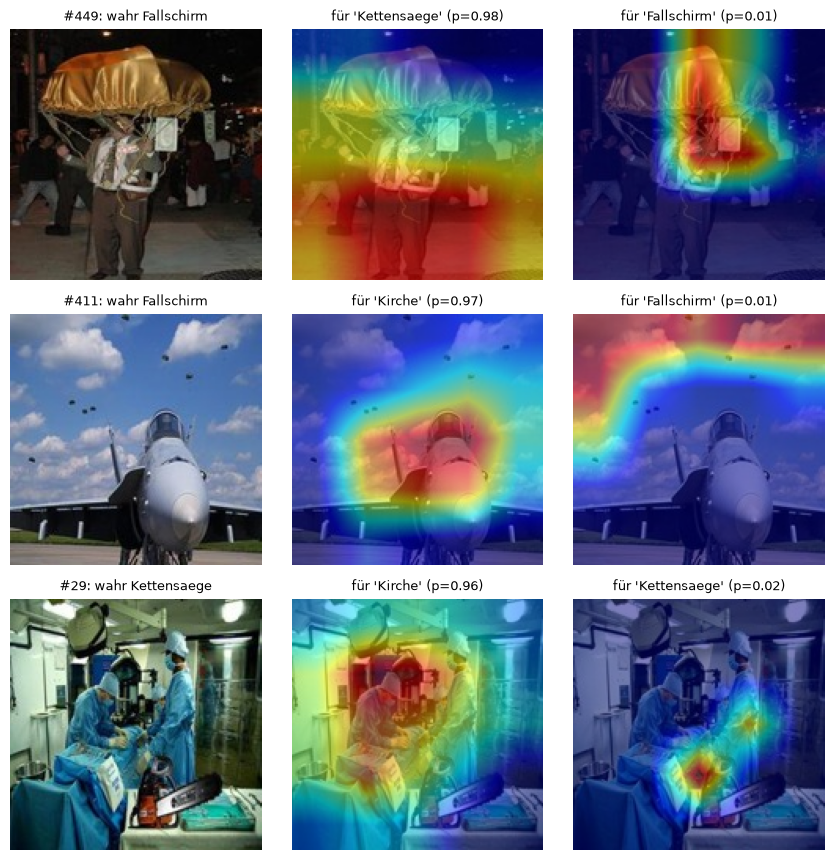

✅ O2 Heatmaps haben Bildgroesse 160x160 und Werte in [0, 1]


In [49]:
abschnitt("Optional O2")
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model.eval()
# TODO O2a: cam = GradCAM(model=model, target_layers=[model.layer4[-1]])   (letzter Residualblock von layer4)
cam = GradCAM(model=model, target_layers=[model.layer4[-1]])
drei = top5[:3]
fig, ax = plt.subplots(len(drei), 3, figsize=(8.6, 2.9 * len(drei)), squeeze=False)
for r, i in enumerate(drei):
    x, t, p = ds_val[i][0], int(y_val[i]), int(pred[i])
    rgb = denorm(x).astype(np.float32)
    # TODO O2b: Heatmaps (H x W, Werte 0..1) fuer die vorhergesagte Klasse p und die wahre Klasse t:
    #           cam(input_tensor=x[None], targets=[ClassifierOutputTarget(p)])[0]
    cam_pred = cam(input_tensor=x[None], targets=[ClassifierOutputTarget(p)])[0]
    cam_true = cam(input_tensor=x[None], targets=[ClassifierOutputTarget(t)])[0]
    ax[r, 0].imshow(rgb); ax[r, 0].set_title(f"#{i}: wahr {CLASSES[t]}", fontsize=9)
    ax[r, 1].imshow(show_cam_on_image(rgb, cam_pred, use_rgb=True)); ax[r, 1].set_title(f"für '{CLASSES[p]}' (p={probs[i, p]:.2f})", fontsize=9)
    ax[r, 2].imshow(show_cam_on_image(rgb, cam_true, use_rgb=True)); ax[r, 2].set_title(f"für '{CLASSES[t]}' (p={probs[i, t]:.2f})", fontsize=9)
    for a in ax[r]:
        a.axis("off")
plt.tight_layout(); plt.show()
check("O2 Heatmaps haben Bildgroesse 160x160 und Werte in [0, 1]",
      lambda: cam_pred.shape == cam_true.shape == (160, 160) and 0 <= cam_pred.min() and cam_pred.max() <= 1)

### O3 · Normalisierung weglassen

`CODE` + `AUSFÜHREN` · Skript Abschn. 5.2, Detail 1. Dieselben Bilder ohne ImageNet-Normalisierung, derselbe eingefrorene Backbone,
derselbe Kopf (Lernrate aus 4.3). Das ist Data Drift im Kleinen: Die Eingabeverteilung weicht von der im Pretraining ab.
**Rechenzeit ≈ 1 Min.** (neue Feature-Extraktion, danach im Cache).

In [50]:
abschnitt("Optional O3")
# TODO O3: Train- und Val-Datensatz wie in 4.2, aber mit make_transform(normalize=False)
ds_train_nn = Imagenette5(IMG, "train", make_transform(normalize=False))
ds_val_nn   = Imagenette5(IMG, "val",   make_transform(normalize=False))
torch.manual_seed(0)
backbone0 = nn.Sequential(*list(build_model(5, WEIGHTS).children())[:-1], nn.Flatten())   # Original-Backbone (model hat ein neues layer4)
feat_nn = {s: cached_features(backbone0, ds, f"features_resnet18_160_nonorm_{s}") for s, ds in [("train", ds_train_nn), ("val", ds_val_nn)]}
dl_nn = {"train": DataLoader(TensorDataset(feat_nn["train"]["x"], feat_nn["train"]["y"]), batch_size=64, shuffle=True),
         "val":   DataLoader(TensorDataset(feat_nn["val"]["x"],   feat_nn["val"]["y"]),   batch_size=256)}
head_nn, h_nn = train_head(best_lr, dl_nn)
acc_nn = run_epoch(head_nn, dl_nn["val"])[1]
display(pd.DataFrame({"mit Normalisierung (4.3)": [f"{acc_fe:.2%}", f"{min(h_fe['val_loss']):.4f}", f"{feat['val']['x'].mean():.3f}", f"{feat['val']['x'].std():.3f}"],
                      "ohne Normalisierung": [f"{acc_nn:.2%}", f"{min(h_nn['val_loss']):.4f}", f"{feat_nn['val']['x'].mean():.3f}", f"{feat_nn['val']['x'].std():.3f}"]},
                     index=["Val-Genauigkeit", "min. Val-Verlust", "Mittelwert Features", "Std Features"]))
save_log("o3_nonorm", h_nn, config=dict(normalize=False, lr=best_lr, epochs=10, batch=64), val_acc=acc_nn,
         val_acc_with_norm=acc_fe, min_val_loss_with_norm=min(h_fe["val_loss"]),
         seconds={s: feat_nn[s].get("seconds") for s in feat_nn})
check("O3 ohne Normalisierung ist der Val-Verlust hoeher als mit", min(h_nn["val_loss"]) > min(h_fe["val_loss"]))

features_resnet18_160_nonorm_train: aus Cache geladen (2500, 512)
features_resnet18_160_nonorm_val: aus Cache geladen (500, 512)


,mit Normalisierung (4.3),ohne Normalisierung
Val-Genauigkeit,98.80%,95.80%
min. Val-Verlust,0.0348,0.0964
Mittelwert Features,1.112,0.946
Std Features,1.242,1.059


✅ O3 ohne Normalisierung ist der Val-Verlust hoeher als mit


### O4 · im2col: Faltung als Matrixmultiplikation

`CODE` · Alle $M\times M$-Ausschnitte werden Zeilen einer Matrix ($J'K'\times M^2$); die ganze Faltung ist dann **eine**
Multiplikation mit dem Kernel als Vektor. So rechnen Bibliotheken Faltungen auf GEMM-Routinen. Laufzeitvergleich mit `timeit`.

In [51]:
abschnitt("Optional O4")
from numpy.lib.stride_tricks import sliding_window_view
from timeit import timeit

def conv2d_im2col(I: np.ndarray, K: np.ndarray, P: int = 0, S: int = 1) -> np.ndarray:
    """Faltung wie conv2d_np, aber ohne Python-Schleife ueber die Positionen."""
    M = K.shape[0]
    Ip = np.pad(I, P)
    # TODO O4: fenster = sliding_window_view(Ip, (M, M))[::S, ::S] hat die Form (J', K', M, M) -- alle Ausschnitte.
    #          Zu (J'*K', M*M) umformen, mit K.ravel() multiplizieren (.dot oder @) und das Ergebnis zu (J', K') formen.
    #          (Auf macOS meldet @ mit NumPy 2.0 manchmal harmlose RuntimeWarnings; das Ergebnis stimmt trotzdem.)
    fenster = sliding_window_view(Ip, (M, M))[::S, ::S]
    Jo, Ko = fenster.shape[:2]
    return fenster.reshape(Jo * Ko, M * M).dot(K.ravel()).reshape(Jo, Ko)

In [52]:
# Pruefzelle O4 und Laufzeitvergleich
check("O4 im2col == conv2d_np auf Abb. 2 (P=0, S=1 und P=1, S=2)",
      lambda: np.allclose(conv2d_im2col(I_fig, K_fig), C_fig) and np.allclose(conv2d_im2col(I_fig, K_fig, 1, 2), C_ps))
rng = np.random.default_rng(0)
_I, _K = rng.normal(size=(28, 28)), rng.normal(size=(5, 5))
check("O4 im2col == conv2d_np auf 28x28, 5x5, P=2", lambda: np.allclose(conv2d_im2col(_I, _K, 2), conv2d_np(_I, _K, 2)))

zeilen = []
for J in (28, 160):
    I_t, K_t = rng.normal(size=(J, J)), rng.normal(size=(3, 3))
    It, Kt = torch.tensor(I_t, dtype=torch.float32)[None, None], torch.tensor(K_t, dtype=torch.float32)[None, None]
    n = 20 if J == 28 else 3
    t = {"Doppelschleife": timeit(lambda: conv2d_np(I_t, K_t, P=1), number=n) / n,
         "im2col": timeit(lambda: conv2d_im2col(I_t, K_t, P=1), number=n) / n,
         "F.conv2d": timeit(lambda: F.conv2d(It, Kt, padding=1), number=n) / n}
    zeilen.append({"Bild": f"{J}x{J}", **{k: v * 1e3 for k, v in t.items()}, "Faktor Schleife/im2col": t["Doppelschleife"] / t["im2col"]})
zeit_tab = pd.DataFrame(zeilen).set_index("Bild")
save_log("o4_im2col", config=dict(kernel="3x3", padding=1, sizes=[28, 160]), timing_ms=zeit_tab.to_dict(orient="index"))
display(zeit_tab.round(3).rename(columns={"Doppelschleife": "Doppelschleife (ms)", "im2col": "im2col (ms)", "F.conv2d": "F.conv2d (ms)"}))

✅ O4 im2col == conv2d_np auf Abb. 2 (P=0, S=1 und P=1, S=2)
✅ O4 im2col == conv2d_np auf 28x28, 5x5, P=2


,Doppelschleife (ms),im2col (ms),F.conv2d (ms),Faktor Schleife/im2col
Bild,,,,
28x28,0.917,0.376,0.030,2.440
160x160,27.019,0.420,0.036,64.367


### Interpretation Aufgabe O

`DENKEN` · Leitfragen zum Selbststudium:
- O2: Hat das Netz bei den drei Fehlern auf das Objekt oder auf den Hintergrund geschaut? Passt das zu Ihrer Kategorie aus 5.4?
- O3: Wie stark schadet die fehlende Normalisierung, und warum gehört sie deshalb zum Modell (YAML) statt ins Notebook?
- O4: Warum ist im2col so viel schneller als die Doppelschleife, obwohl es dieselben Multiplikationen ausführt? Was kostet es?

**Antwort (Musterlösung):**


- **O1:** Alle vier IoU-Tests bestehen (1 / 0 / $1/7\approx0{,}143$ / 0,25). YOLO für $S=7$, $B=2$, $C=20$ gibt
  $7\cdot7\cdot(5\cdot2+20)=1\,470$ Zahlen aus (Def. 6.2).
- **O2 (Grad-CAM, Gl. 9):** Bei allen drei Fehlern liegt die Heatmap der **wahren** Klasse auf dem richtigen Objekt: Schirm (#449),
  Himmel mit den winzigen Springern (#411), Kettensäge auf dem OP-Tisch (#29). Das Netz hat das Objekt gefunden, aber der Kontext
  hat gewonnen. „Kirche“ stützt sich in #29 auf Decke und Leuchten des OP-Saals (vgl. Kirchen-Innenaufnahmen im Bildraster) und in
  #411 auf Cockpit und Rumpfspitze des Jets; „Kettensäge“ in #449 auf Person und Unterkörper. Das bestätigt die Kategorien
  *Kurzschluss über Kontext* bzw. *Verteilungsverschiebung* aus 5.4 und zeigt: Hohe Genauigkeit ist kein Beleg für robuste Merkmale (Abschn. 8.3).
- **O3 (ohne Normalisierung):** Val-Genauigkeit **95,8 %** statt 98,8 %, minimaler Val-Verlust 0,096 statt 0,035. Die Features sind
  verschoben (Mittelwert 0,95 statt 1,11, Std 1,06 statt 1,24). Das ist Data Drift im Kleinen (Abschn. 5.2, Detail 1): Eine
  Vorverarbeitung, die vom Pretraining abweicht, verschiebt die Eingabeverteilung aller Schichten. Deshalb steht die Normalisierung
  in `traeger_v1.yaml` und nicht im Notebook. Rechenzeit 21 s.
- **O4 (im2col):** Gleiche Ergebnisse wie die Doppelschleife. $3\times3$-Kernel, same: 28 × 28 in 0,95 ms (Schleife) gegen 0,053 ms
  (im2col, Faktor 18) und 0,005 ms (`F.conv2d`); 160 × 160 in 31,1 ms gegen 0,58 ms (Faktor 54) und 0,067 ms
  (Mikro-Messungen, schwanken von Lauf zu Lauf um bis zu Faktor 2). Beide Varianten führen
  dieselben Multiplikationen aus, im2col aber in **einer** BLAS-Operation statt in $J'K'$ Python-Schritten. Der Preis ist Speicher:
  Die Matrix hat $J'K'\cdot M^2$ Einträge, bei 160 × 160 also das Neunfache des Bildes.

## Laufzeiten und Prüfungen

`AUSFÜHREN` · Reine Rechenzeit je Aufgabe (Summe der Zellen, ohne Ihre Denkpausen) und Übersicht aller Prüfungen.

In [53]:
abschnitt("Abschluss")
display(pd.DataFrame({"Rechenzeit (s)": RUNTIME}).round(1))
pflicht = sum(v for k, v in RUNTIME.items() if k.startswith("Aufgabe"))
optional = sum(v for k, v in RUNTIME.items() if k.startswith("Optional"))
print(f"Pflichtteil (Aufgaben 0-5): {pflicht / 60:.1f} Min. | Optional: {optional / 60:.1f} Min. "
      f"| Threads: {torch.get_num_threads()}")
print(f"Pruefungen: {sum(CHECKS.values())} ✅ / {sum(not v for v in CHECKS.values())} ❌")
for name, ok in CHECKS.items():
    if not ok:
        print("  ❌", name)

,Rechenzeit (s)
Aufgabe 0,0.3
Aufgabe 1,0.1
Aufgabe 2,0.0
Aufgabe 3,28.8
Aufgabe 4,82.2
Aufgabe 5,5.9
Optional O1,0.0
Optional O2,1.0
Optional O3,0.3
Optional O4,0.1


Pflichtteil (Aufgaben 0-5): 2.0 Min. | Optional: 0.0 Min. | Threads: 10
Pruefungen: 67 ✅ / 0 ❌


## Abgabe-Checkliste

- [ ] Datei heißt `lab02_<nachname>.ipynb` und läuft mit *Kernel → Restart & Run All* durch (abgebrochene Läufe sind markiert und durch `results_referenz/` ersetzt)
- [ ] Alle Prüfzellen der Aufgaben 1–5 zeigen ✅
- [ ] Interpretationen zu Aufgabe 1–5 und die Tabelle in 5.4 sind ausgefüllt (Stichpunkte, mit Skript-Bezug)
- [ ] `models/traeger_v1.pt` und `models/traeger_v1.yaml` liegen im Repository-Ordner `models/`; der Ladetest in 4.5 ist grün
- [ ] Dateinamen und Schlüssel des Trägermodells unverändert – die Labs ab *Daten-Engineering für ML* bauen darauf auf
- [ ] `results/` enthält die JSON-Logs Ihrer Läufe